# 15 · Multi-Agent Patterns: Supervisor, Swarm, Hierarchical

Three ways to organise agents, each judged on the same task.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AfzalManihar/Agentic-AI-Learning/blob/main/15_multi_agent_patterns.ipynb)

**Covered in this notebook**

- Supervisor / Orchestrator Pattern
- Swarm Pattern
- Hierarchical Agents
- 🏢 Hierarchical Agents — CEO → Directors → Workers
- 🏁 Take-aways

> Part of [Agentic AI Learning](https://github.com/AfzalManihar/Agentic-AI-Learning). Add your own API keys in Colab Secrets (key icon) before running.

#04-10-2026
#Multi-Agent System Architecture

# Supervisor / Orchestrator Pattern

In [ ]:
# ---------- Cell 1: Install the library + load the Groq API key ----------

# "groq" is the official Groq library. We use it directly (no LangChain, no LangGraph) to keep the code simple.
%pip install -q groq

import os
from getpass import getpass


def load_api_key() -> str:
    """Find the Groq API key: Colab Secrets first, then the environment, then ask."""

    try:
        from google.colab import userdata                  # only exists inside Colab

        # Your Colab Secret name
        try:
            return userdata.get("groq_api3")
        except Exception:
            pass

    except ImportError:
        pass                                               # not running in Colab

    return os.environ.get("GROQ_API_KEY") or getpass("Enter your Groq API key: ")


API_KEY = load_api_key()

print("API key loaded:", bool(API_KEY))                    # prints True/False, the key itself is never printed

API key loaded: True


In [ ]:
# ---------- Cell 2: Helper functions (used by every cell after this) ----------

import json
import re
import textwrap
import time

from groq import Groq

MODEL = "openai/gpt-oss-120b"        # one model for everything; "different agents" = different prompts
client = Groq(api_key=API_KEY)

LLM_CALLS = {"count": 0}             # counts every call, so we can compare the cost of different designs later


def chat(messages: list, as_json: bool = False) -> str:
    """Send a list of messages to the model and return the reply text. Waits and retries on rate limits."""
    LLM_CALLS["count"] += 1
    options = {"response_format": {"type": "json_object"}} if as_json else {}
    for attempt in range(6):
        try:
            response = client.chat.completions.create(model=MODEL, messages=messages, temperature=0, **options)
            return response.choices[0].message.content or ""
        except Exception as error:
            if "rate_limit" not in str(error) and "429" not in str(error):
                raise                                            # a different error: show it, do not hide it
            found = re.search(r"try again in ([0-9.]+)(ms|s)", str(error))
            wait = 5.0 * (attempt + 1)                           # default wait if the error does not say how long
            if found:
                wait = float(found.group(1)) / (1000 if found.group(2) == "ms" else 1) + 1.0
            print(f"   (rate limit reached, waiting {wait:.1f}s)")
            time.sleep(wait)
    raise RuntimeError("Still rate limited after 6 tries. Wait a minute and run the cell again.")


def ask(system: str, user: str) -> str:
    """One question, one answer: a system prompt (the agent's role) plus a user message."""
    return chat([{"role": "system", "content": system}, {"role": "user", "content": user}])


def ask_json(system: str, user: str) -> dict:
    """Same as ask(), but the reply is JSON and is returned as a Python dict. Retries if the JSON is broken."""
    if "json" not in system.lower():
        system += "\nReply ONLY with a valid JSON object."     # Groq's JSON mode requires the word JSON in the prompt
    for _ in range(3):
        try:
            return json.loads(chat([{"role": "system", "content": system}, {"role": "user", "content": user}], as_json=True))
        except json.JSONDecodeError:
            time.sleep(1)                                        # empty or broken JSON happens now and then: try again
    raise RuntimeError("The model did not return valid JSON after 3 tries.")


def show(icon: str, title: str, text: str = "") -> None:
    """Print a titled block. Every step of the supervisor/workers will be printed with this."""
    print(f"\n{icon} {title}")
    if text:
        print(textwrap.indent(text, "   "))


# ---------- Smoke tests ----------
print(ask("You are a helpful assistant.", "Reply with exactly three words: connection is working"))
print(ask_json("Reply with JSON.", 'Return {"status": "json is working"}'))
show("🧠", "SUPERVISOR (example block)", "Blocks like this will show every step later.")

print("\nLLM calls so far:", LLM_CALLS["count"])
LLM_CALLS["count"] = 0               # do not count the smoke tests

connection is working
{'status': 'json is working'}

🧠 SUPERVISOR (example block)
   Blocks like this will show every step later.

LLM calls so far: 2


In [ ]:
# ---------- Cell 3: Why multi-agent? Reason 1 - CONTEXT LIMITS ----------

# Your notes: a single agent working on a long task fills its context window with every question, answer,
# tool call and observation. Splitting the work across agents gives each one a clean, focused context.
#
# Here we do 6 small steps two ways and measure how much text the model must read at each step:
#   (A) ONE agent : a single conversation, so the history keeps growing
#   (B) SEPARATE agents : every step starts fresh
# We measure in characters (simple and good enough to see the trend).

topics = ["bandwidth", "latency", "fibre broadband", "5G", "a data cap", "a router"]
SYSTEM = "You are a helpful assistant. Answer in 2 short sentences."


def context_size(messages: list) -> int:
    """How many characters the model has to read for this call."""
    return sum(len(m["content"]) for m in messages)


# ---------- (A) One single agent: everything stays in ONE conversation ----------
print("(A) ONE agent, one growing conversation")
history = [{"role": "system", "content": SYSTEM}]
single_sizes = []
for number, topic in enumerate(topics, start=1):
    history.append({"role": "user", "content": f"Explain {topic}."})
    single_sizes.append(context_size(history))                    # what the model reads for THIS step
    reply = chat(history)
    history.append({"role": "assistant", "content": reply})       # the answer is added to the history too
    print(f"   step {number}: the model reads {single_sizes[-1]:>4} characters")

# ---------- (B) Separate agents: every step starts with a clean context ----------
print("\n(B) SEPARATE agents, each step starts fresh")
separate_sizes = []
for number, topic in enumerate(topics, start=1):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"Explain {topic}."}]
    separate_sizes.append(context_size(messages))
    chat(messages)
    print(f"   step {number}: the model reads {separate_sizes[-1]:>4} characters")

# ---------- Compare ----------
print("\nCOMPARISON")
print(f"   last step : one agent reads {single_sizes[-1]} characters, separate agent reads {separate_sizes[-1]}")
print(f"   all steps : one agent read {sum(single_sizes)} characters in total, separate agents read {sum(separate_sizes)}")
print("\nNote: this model has a very large context window, so with only 6 tiny steps it will not actually forget")
print("anything. The point is the GROWTH. In real tasks, tool outputs make every step much bigger, and a long")
print("history costs more, runs slower and buries the important details (your notes: 'by step 15 it has forgotten step 2').")

LLM_CALLS["count"] = 0

(A) ONE agent, one growing conversation
   step 1: the model reads   75 characters
   step 2: the model reads  312 characters
   step 3: the model reads  521 characters
   step 4: the model reads  840 characters
   step 5: the model reads 1170 characters
   step 6: the model reads 1426 characters

(B) SEPARATE agents, each step starts fresh
   step 1: the model reads   75 characters
   step 2: the model reads   73 characters
   step 3: the model reads   81 characters
   step 4: the model reads   68 characters
   step 5: the model reads   76 characters
   step 6: the model reads   74 characters

COMPARISON
   last step : one agent reads 1426 characters, separate agent reads 74
   all steps : one agent read 4344 characters in total, separate agents read 447

Note: this model has a very large context window, so with only 6 tiny steps it will not actually forget
anything. The point is the GROWTH. In real tasks, tool outputs make every step much bigger, and a long
history costs more, runs s

In [ ]:
# ---------- Cell 4: Why multi-agent? Reason 2 - SPECIALISATION ----------

# Your notes: one agent told to be researcher + writer + critic + fact-checker at the same time does worse
# than separate agents, each deeply prompted for ONE role. Same model, different system prompt -> different behaviour.
# Test: both agents get the SAME facts and the SAME draft. The draft hides 3 mistakes. Who finds them?

DRAFT_FACTS = "FiberNet Basic: price 499 INR per month, data cap 300 GB per month, speed 100 Mbps."

DRAFT = (
    "FiberNet Basic costs 499 INR per month and is obviously the cheapest plan in the world. "
    "It comes with unlimited data and the fastest speed ever recorded, so everyone should buy it today."
)

# The 3 hidden mistakes. We know them, so we can check the answers automatically (by looking for the keyword).
MISTAKES = {
    "'cheapest plan in the world' (no proof)": "cheapest",
    "'unlimited data' (the facts say a 300 GB cap)": "unlimited",
    "'fastest speed ever recorded' (no proof)": "fastest",
}

# Agent 1: a generalist who does everything.  Agent 2: a specialist with ONE narrow job.
GENERALIST = "You are a helpful assistant. You research, write, critique and fact-check, all in one."
SPECIALIST = (
    "You are a strict fact-checker and ONLY a fact-checker. List every claim in the text that is exaggerated "
    "or not supported by the facts, one short bullet per claim, and say why. "
    "Do not rewrite the text and do not praise it."
)

request = f"Facts:\n{DRAFT_FACTS}\n\nText to review:\n{DRAFT}\n\nReview the text."

generalist_answer = ask(GENERALIST, request)
specialist_answer = ask(SPECIALIST, request)

show("🧑", "GENERALIST (does everything) answered", generalist_answer)
show("🕵️", "SPECIALIST (only fact-checks) answered", specialist_answer)

# ---------- Which hidden mistakes did each agent mention? ----------
print("\nHidden mistakes found:")
scores = {}
for who, answer in [("generalist", generalist_answer), ("specialist", specialist_answer)]:
    found = [mistake for mistake, keyword in MISTAKES.items() if keyword in answer.lower()]
    scores[who] = len(found)
    print(f"\n  {who}: {len(found)} of {len(MISTAKES)}   ({len(answer.split())} words)")
    for mistake, keyword in MISTAKES.items():
        print(f"     {'✅' if keyword in answer.lower() else '❌'} {mistake}")

print("\nNote: both agents may find all 3. The difference is often FOCUS: the specialist gives a clean list,")
print("while the generalist mixes review, praise and rewriting. Results vary a little from run to run.")

LLM_CALLS["count"] = 0


🧑 GENERALIST (does everything) answered
   **Fact‑check of the statement**

   | Claim in the text | What the provided facts say | Verdict |
   |-------------------|----------------------------|---------|
   | **Price:** “499 INR per month” | **Matches** the official price (499 INR/month). | ✅ Accurate |
   | **Cheapest plan in the world** | No comparative data is supplied. Other ISPs in India (and globally) offer plans at the same price or lower (e.g., some 4G/5G data‑only plans, promotional broadband offers). Without a comprehensive market survey, the “cheapest in the world” claim is **unsubstantiated**. | ❌ Unverified / potentially false |
   | **Data allowance:** “unlimited data” | The plan actually has a **300 GB monthly cap**. After the cap is reached, speed may be throttled or the service may be suspended until the next billing cycle. | ❌ False |
   | **Speed:** “the fastest speed ever recorded” | The advertised speed is **100 Mbps**. While 100 Mbps is respectable for a residen

In [ ]:
# ---------- Cell 5: Why multi-agent? Reason 3 - PARALLELISM ----------

# Your notes: some tasks are genuinely parallelisable. Researching five topics at the same time is much faster
# with five agents than doing them one after another with one agent.
# Waiting for the model is just waiting for the network, so Python threads work well here.

from concurrent.futures import ThreadPoolExecutor

topics_to_research = ["a VPN", "DNS", "IPv6", "a CDN", "Wi-Fi 6"]


def research(topic: str) -> str:
    """One researcher agent, one topic."""
    return ask("You are a researcher. Answer in ONE sentence.", f"Explain {topic}.")


# ---------- (A) ONE agent, topics one after another ----------
start = time.time()
sequential_answers = [research(topic) for topic in topics_to_research]
sequential_time = time.time() - start

# ---------- (B) FIVE agents at the same time: every topic gets its own thread ----------
start = time.time()
with ThreadPoolExecutor(max_workers=len(topics_to_research)) as pool:
    parallel_answers = list(pool.map(research, topics_to_research))    # results come back in the same order
parallel_time = time.time() - start

# ---------- Results ----------
for topic, answer in zip(topics_to_research, parallel_answers):
    show("🤖", f"Researcher on {topic}", answer)

print(f"\n(A) one agent, one after another : {sequential_time:.1f} seconds")
print(f"(B) five agents, at the same time : {parallel_time:.1f} seconds")
print(f"    -> about {sequential_time / parallel_time:.1f}x faster")
print("\nNote: you will see a speed-up close to, but usually below, 5x (network overhead, rate limits).")
print("It only works because the five topics do NOT depend on each other. Steps that need the previous result")
print("(for example research -> calculate -> write) cannot be run in parallel.")

LLM_CALLS["count"] = 0


🤖 Researcher on a VPN
   A VPN (Virtual Private Network) encrypts your internet traffic and routes it through a remote server, creating a secure, private tunnel that masks your IP address and protects data from eavesdropping.

🤖 Researcher on DNS
   DNS (Domain Name System) is a hierarchical, distributed database that translates human‑readable domain names into IP addresses, allowing users and applications to locate computers and services on the Internet.

🤖 Researcher on IPv6
   IPv6 is the next‑generation Internet Protocol that uses 128‑bit addresses (allowing about 3.4×10³⁸ unique IPs), incorporates built‑in security, simplified header processing, and auto‑configuration features to replace IPv4’s limited 32‑bit address space.

🤖 Researcher on a CDN
   A CDN (Content Delivery Network) is a globally distributed system of edge servers that caches and delivers web content (e.g., images, videos, scripts) to users from the nearest location, reducing latency, bandwidth costs, and improvin

In [ ]:
# ---------- Cell 6: The workers (researcher, analyst, writer) ----------

# A worker = the same model + its own system prompt. That is all "specialisation" means in practice.
# Workers never talk to each other. They only receive a task and return an answer to the supervisor.

# A tiny fake knowledge base. Only the researcher can see it (like a database only that worker may query).
# NOTE the surprise: "AirWave 5G" is DISCONTINUED and replaced by "AirWave 5G Plus". We use it in Cell 9.
FACTS = """
FiberNet Basic: price 499 INR per month, data 300 GB per month, speed 100 Mbps.
AirWave 5G: DISCONTINUED. It has been replaced by AirWave 5G Plus.
AirWave 5G Plus: price 699 INR per month, data 600 GB per month, speed 200 Mbps.
"""

WORKERS = {
    "researcher": {
        "info": "looks up the price, data and speed of internet plans (or their status) in the facts",
        "prompt": (
            "You are a researcher. You only know the FACTS below. When you are asked about a plan, report "
            "exactly what the facts say about THAT plan (price, data, speed, or its status). "
            "If the facts say nothing about it, answer 'no information'. "
            "Do not look up any plan you were not asked about. Do not calculate and do not recommend.\n"
            f"FACTS:{FACTS}"
        ),
    },
    "analyst": {
        "info": "does calculations such as price per GB, using only the numbers given in the task",
        "prompt": (
            "You are an analyst. Do the calculation you are asked to do, using ONLY the numbers given to you "
            "in the task. Show the formula and the result rounded to 2 decimals. If a number is missing, say "
            "exactly which number is missing and do NOT invent it. Do not recommend anything."
        ),
    },
    "writer": {
        "info": "writes the final short recommendation from the facts and numbers given to it",
        "prompt": (
            "You are a writer. Write a short recommendation (3-4 sentences) using ONLY the facts and numbers "
            "you are given. If information is missing, or a plan is discontinued and no numbers are given for "
            "it, say so honestly. Never invent data."
        ),
    },
}


def run_worker(name: str, task: str) -> str:
    """Give one task to one worker and return its answer."""
    if name not in WORKERS:                       # a careless supervisor may ask for a worker that does not exist
        show("⚠️", f"There is no worker called '{name}'", "The supervisor asked for a worker that does not exist.")
        return f"ERROR: there is no worker called '{name}'."
    show("📝", f"{name.upper()} received this task", task)
    answer = ask(WORKERS[name]["prompt"], task)
    show("🤖", f"{name.upper()} answered", answer)
    return answer


# ---------- Quick tests: see how each worker behaves ----------
run_worker("researcher", "Find the price, data and speed of FiberNet Basic.")
run_worker("researcher", "Find the price, data and speed of AirWave 5G.")        # the discontinued plan
run_worker("analyst", "Calculate the price per GB of AirWave 5G.")               # no numbers given on purpose

LLM_CALLS["count"] = 0


📝 RESEARCHER received this task
   Find the price, data and speed of FiberNet Basic.

🤖 RESEARCHER answered
   FiberNet Basic: price 499 INR per month, data 300 GB per month, speed 100 Mbps.

📝 RESEARCHER received this task
   Find the price, data and speed of AirWave 5G.

🤖 RESEARCHER answered
   no information

📝 ANALYST received this task
   Calculate the price per GB of AirWave 5G.

🤖 ANALYST answered
   To calculate the price per GB, I need two numbers:

   1. **The total price of AirWave 5G** (in your chosen currency).  
   2. **The total data amount** that the price covers (in gigabytes, GB).

   Since neither of these numbers was provided, I cannot perform the calculation. Please supply the price and the data amount, and I’ll compute the price per GB for you.


In [ ]:
# ---------- Cell 7: The supervisor at work (what it REALLY does, not just routing) ----------

# Your notes: the supervisor does more than route tasks. It has four jobs:
#   JOB 1  DECOMPOSE  : break the task into small sub-tasks, each for the right worker, in the right order
#   JOB 2  DELEGATE   : write each worker's task (adding earlier results, because workers cannot talk to each other)
#   JOB 3  EVALUATE   : check every result; if it is poor, send the worker back with feedback (retry)
#   JOB 4  SYNTHESISE : merge all results into ONE final answer

TEAM = "\n".join(f"- {name}: {worker['info']}" for name, worker in WORKERS.items())

# The GOOD supervisor prompt: it knows its workers, the order, and demands clear self-contained sub-tasks.
GOOD_DECOMPOSE_PROMPT = (
    "You are a supervisor agent. Break the user's task into small sub-tasks.\n"
    f"Your workers:\n{TEAM}\n"
    "Rules:\n"
    "- Give each sub-task to exactly ONE worker, the one whose skill fits it.\n"
    "- Order matters: facts first (researcher), then calculations (analyst), then writing (writer).\n"
    "- Every sub-task must be clear on its own and name the exact plans (for example 'FiberNet Basic').\n"
    "- Workers cannot talk to each other. The results of earlier workers are passed on automatically.\n"
    'Reply with JSON: {"thought": "your reasoning", "subtasks": [{"worker": "researcher", "task": "..."}]}'
)


# ---------- JOB 1: DECOMPOSE ----------
def decompose(task: str, prompt: str = GOOD_DECOMPOSE_PROMPT) -> list:
    out = ask_json(prompt, task)
    show("🧠", "SUPERVISOR - job 1: DECOMPOSE the task", out.get("thought", ""))
    plan = [s for s in out.get("subtasks", []) if "worker" in s and "task" in s]
    for number, sub in enumerate(plan, start=1):
        show("📋", f"Sub-task {number} -> {sub['worker']}", sub["task"])
    return plan


# ---------- JOB 3: EVALUATE (and retry once if the result is poor) ----------
REVIEW_PROMPT = (
    "You are a supervisor checking a worker's result. Decide if the result properly completes the sub-task.\n"
    "good_enough is true when the result contains what the sub-task asked for. An honest 'no information' or "
    "'discontinued' is a valid result. good_enough is false when the result is off-topic, empty, invents data, "
    "or misses something the sub-task clearly asked for.\n"
    'Reply with JSON: {"good_enough": true, "feedback": "what to fix (empty if fine)"}'
)


def evaluate(worker: str, subtask: str, task_text: str, result: str) -> str:
    verdict = ask_json(REVIEW_PROMPT, f"SUB-TASK: {subtask}\n\nRESULT: {result}")
    good = verdict.get("good_enough", True)
    show("🔍", f"SUPERVISOR - job 3: EVALUATE the {worker}'s result",
         f"good enough: {good}" + ("" if good else f"\nfeedback: {verdict.get('feedback', '')}"))
    if good:
        return result
    show("🔁", f"SUPERVISOR sends the task back to the {worker} (retry)")
    return run_worker(worker, task_text + f"\n\nYour previous answer was not good enough. Feedback: {verdict.get('feedback', '')}")


# ---------- JOB 2 (+3): DELEGATE every sub-task, one after another ----------
def delegate(plan: list, check: bool = True) -> list:
    results = []
    for sub in plan:
        task_text = sub["task"]
        if results:   # workers cannot talk to each other, so the supervisor passes the earlier results along
            task_text += "\n\nResults so far:\n" + "\n".join(f"- ({r['worker']}) {r['result']}" for r in results)
        show("📤", f"SUPERVISOR - job 2: DELEGATE to the {sub['worker']}")
        result = run_worker(sub["worker"], task_text)
        if check:
            result = evaluate(sub["worker"], sub["task"], task_text, result)
        results.append({"worker": sub["worker"], "task": sub["task"], "result": result})
    return results


# ---------- JOB 4: SYNTHESISE ----------
def synthesise(task: str, results: list) -> str:
    notes = "\n".join(f"- ({r['worker']}) {r['result']}" for r in results) or "(no results)"
    final = ask(
        "You are the supervisor. Combine the worker results into ONE clear final answer for the user. "
        "Use only facts from the results. If something is missing, say so honestly.",
        f"User task: {task}\n\nWorker results:\n{notes}",
    )
    show("✅", "SUPERVISOR - job 4: SYNTHESISE the final answer", final)
    return final


def static_supervisor(task: str, prompt: str = GOOD_DECOMPOSE_PROMPT, check: bool = True) -> str:
    """Plan everything up front, run every sub-task, then write the final answer."""
    plan = decompose(task, prompt)
    results = delegate(plan, check)
    return synthesise(task, results)


# ---------- A simple automatic check: which key facts does a final answer contain? ----------
KEY_FACTS = {
    "FiberNet Basic price (499)": r"499",
    "AirWave 5G Plus price (699)": r"699",
    "FiberNet price per GB (1.66)": r"1\.66",
    "AirWave 5G Plus price per GB (about 1.17)": r"1\.1[67]",
    "names AirWave 5G Plus": r"AirWave 5G Plus",
}


def check_answer(answer: str) -> int:
    print("\nKey facts in the final answer:")
    found = 0
    for name, pattern in KEY_FACTS.items():
        ok = re.search(pattern, answer, re.IGNORECASE) is not None
        found += ok
        print(f"   {'✅' if ok else '❌'} {name}")
    print(f"   -> {found} of {len(KEY_FACTS)} key facts")
    return found


# ---------- Run the GOOD supervisor on a task where nothing goes wrong ----------
SIMPLE_TASK = (
    "Compare FiberNet Basic and AirWave 5G Plus: find the monthly price and data of each, "
    "calculate the price per GB of each, and write a short recommendation."
)

LLM_CALLS["count"] = 0
final_answer = static_supervisor(SIMPLE_TASK)
print(f"\nLLM calls used: {LLM_CALLS['count']}")
check_answer(final_answer)


🧠 SUPERVISOR - job 1: DECOMPOSE the task
   We need to first gather the required facts about the two plans, then compute price per GB, and finally produce a concise recommendation. The tasks are assigned to the appropriate workers in the required order.

📋 Sub-task 1 -> researcher
   Find the monthly price, data allowance (in GB), and advertised speed for the plans named 'FiberNet Basic' and 'AirWave 5G Plus' from the available facts.

📋 Sub-task 2 -> analyst
   Using the price and data values obtained, calculate the price per GB for 'FiberNet Basic' and for 'AirWave 5G Plus' (price divided by data allowance).

📋 Sub-task 3 -> writer
   Write a short recommendation comparing 'FiberNet Basic' and 'AirWave 5G Plus' based on their price per GB, data limits, and speeds.

📤 SUPERVISOR - job 2: DELEGATE to the researcher

📝 RESEARCHER received this task
   Find the monthly price, data allowance (in GB), and advertised speed for the plans named 'FiberNet Basic' and 'AirWave 5G Plus' from the

5

In [ ]:
# ---------- Cell 8: A BAD supervisor vs a GOOD supervisor (task decomposition is the hardest problem) ----------

# Your notes: "the supervisor's hardest problem is task decomposition". Even excellent workers cannot rescue a bad plan.
# Same task, same workers, same model. The ONLY difference is how the supervisor breaks the task down.
#
# The bad supervisor is bad ON PURPOSE (a prompt that makes typical mistakes), so the difference is easy to see:
#   mistake 1: vague sub-tasks that never name the plans
#   mistake 2: it forgets a step the task needs (nobody ever looks up the facts)

import contextlib
import io

BAD_DECOMPOSE_PROMPT = (
    "You are a careless supervisor in a hurry. Break the user's task into exactly 2 sub-tasks WITHOUT thinking "
    "about the details.\n"
    "Rules you must follow:\n"
    "1) Every sub-task is short and vague (at most 6 words) and never mentions plan names.\n"
    "2) Use only the analyst and the writer, in that order. Skip the researcher, it is slow.\n"
    'Reply with JSON: {"thought": "your reasoning", "subtasks": [{"worker": "analyst", "task": "..."}]}'
)


def run_quietly(task: str, prompt: str):
    """Run decompose -> delegate -> synthesise, but hide the long trace (we print a short report instead)."""
    with contextlib.redirect_stdout(io.StringIO()):
        plan = decompose(task, prompt)
        results = delegate(plan, check=False)         # no evaluation, so ONLY the plan decides the outcome
        final = synthesise(task, results)
    return plan, results, final


def one_line(text: str, limit: int = 110) -> str:
    text = " ".join(text.split())
    return text if len(text) <= limit else text[:limit] + "..."


def report(label: str, plan: list, results: list, final: str) -> int:
    print(f"\n{'=' * 70}\n{label}\n{'=' * 70}")
    print("THE PLAN:")
    for number, sub in enumerate(plan, start=1):
        print(f"   {number}. [{sub['worker']}] {sub['task']}")
    print("\nWHAT EACH WORKER RETURNED:")
    for r in results:
        print(f"   ({r['worker']}) {one_line(r['result'])}")
    print("\nFINAL ANSWER:")
    print(textwrap.indent(final, "   "))
    return check_answer(final)


rows = []
for label, prompt in [("GOOD supervisor", GOOD_DECOMPOSE_PROMPT), ("BAD supervisor (on purpose)", BAD_DECOMPOSE_PROMPT)]:
    LLM_CALLS["count"] = 0
    plan, results, final = run_quietly(SIMPLE_TASK, prompt)
    calls = LLM_CALLS["count"]
    rows.append((label, len(plan), calls, report(label, plan, results, final)))

# ---------- Side by side ----------
print(f"\n{'=' * 70}\nSIDE BY SIDE (same task, same workers, same model)\n{'=' * 70}")
print(f"{'supervisor':<30}{'sub-tasks':>10}{'LLM calls':>12}{'key facts (of 5)':>20}")
for label, n_subtasks, calls, facts in rows:
    print(f"{label:<30}{n_subtasks:>10}{calls:>12}{facts:>20}")

print("\nOnly the plan was different. The workers were equally good in both runs; the bad plan never asked anyone")
print("to look up the facts, so no worker (and no final answer) could be right. Note: we switched the supervisor's")
print("evaluation OFF here. Evaluation sends a worker back to redo ITS task, which cannot fix a plan that is missing a step.")


GOOD supervisor
THE PLAN:
   1. [researcher] Find the monthly price, data allowance (in GB), and advertised speed for the plans named 'FiberNet Basic' and 'AirWave 5G Plus' from the available facts.
   2. [analyst] Using the price and data values obtained, calculate the price per GB for 'FiberNet Basic' and for 'AirWave 5G Plus' (price divided by data allowance).
   3. [writer] Write a short recommendation comparing 'FiberNet Basic' and 'AirWave 5G Plus' based on their price per GB, data limits, and speeds.

WHAT EACH WORKER RETURNED:
   (researcher) FiberNet Basic: price 499 INR per month, data 300 GB per month, speed 100 Mbps. AirWave 5G Plus: price 699 INR...
   (analyst) **FiberNet Basic** Formula: price ÷ data = 499 INR ÷ 300 GB Result: 1.66 INR per GB (rounded to 2 decimals) **...
   (writer) AirWave 5G Plus offers a better value, costing only 1.17 INR per GB compared with 1.66 INR per GB for FiberNet...

FINAL ANSWER:
   **Comparison of FiberNet Basic vs. AirWave 5G Plus**

   

In [ ]:
# ---------- Cell 9: STATIC vs DYNAMIC supervision (what happens when something unexpected shows up?) ----------

# Your notes:
#   STATIC  : the supervisor decides the FULL plan up front and delegates everything at once. Fast, but brittle
#             if an early sub-task gives an unexpected result.
#   DYNAMIC : the supervisor delegates ONE task at a time, reads the result, then decides what to do next.
#             More flexible, but slower.
# The test: "AirWave 5G" is DISCONTINUED (replaced by "AirWave 5G Plus"). The user does not know that.

import contextlib
import io


# ---------- Small fix: ignore special spaces when checking (the model sometimes writes non-breaking spaces) ----------
def check_answer(answer: str) -> int:
    answer = " ".join(answer.split())                   # turns every kind of space into a normal space
    print("\nKey facts in the final answer:")
    found = 0
    for name, pattern in KEY_FACTS.items():
        ok = re.search(pattern, answer, re.IGNORECASE) is not None
        found += ok
        print(f"   {'✅' if ok else '❌'} {name}")
    print(f"   -> {found} of {len(KEY_FACTS)} key facts")
    return found


TRICKY_TASK = (
    "Compare FiberNet Basic and AirWave 5G: find the monthly price and data of each, "
    "calculate the price per GB of each, and write a short recommendation."
)

# ---------- The DYNAMIC supervisor: one step at a time, reading every result before it decides ----------
DYNAMIC_PROMPT = (
    "You are a supervisor agent working step by step.\n"
    f"Your workers:\n{TEAM}\n"
    "Look at the task and the results so far, then decide ONLY the NEXT single step.\n"
    "Read the results carefully. If something unexpected happened (a plan is discontinued, data is missing), "
    "change your plan to handle it, for example by looking up the replacement plan.\n"
    "Order: facts (researcher) -> calculations (analyst) -> writing (writer). "
    "Answer FINISH only after the writer has written the recommendation.\n"
    "Name the exact plans in every sub-task.\n"
    'Reply with JSON: {"thought": "what the results so far tell you", '
    '"next": "researcher or analyst or writer or FINISH", "subtask": "what that worker should do (empty if FINISH)"}'
)


def dynamic_supervisor(task: str, max_steps: int = 6):
    """Decide ONE step, run it, read the result, decide again. Stops at FINISH (or after max_steps)."""
    results = []
    for step in range(1, max_steps + 1):
        done = "\n".join(f"- ({r['worker']}) {r['result']}" for r in results) or "(nothing done yet)"
        out = ask_json(DYNAMIC_PROMPT, f"Task: {task}\n\nResults so far:\n{done}")
        worker = out.get("next", "FINISH")
        show("🧠", f"SUPERVISOR - step {step}: reads the results so far and decides", out.get("thought", ""))
        if worker not in WORKERS:                        # FINISH (or an invented worker): stop planning
            break
        subtask = out.get("subtask", "")
        show("📋", f"NEXT -> {worker}", subtask)
        task_text = subtask + (f"\n\nResults so far:\n{done}" if results else "")
        with contextlib.redirect_stdout(io.StringIO()):  # hide the worker's long trace, print one line instead
            result = run_worker(worker, task_text)
        print(f"   🤖 {worker} answered: {one_line(result)}")
        results.append({"worker": worker, "task": subtask, "result": result})
    with contextlib.redirect_stdout(io.StringIO()):
        final = synthesise(task, results)
    return results, final


# ---------- Run the STATIC supervisor (plan once, no checking in between) ----------
LLM_CALLS["count"] = 0
static_plan, static_results, static_final = run_quietly(TRICKY_TASK, GOOD_DECOMPOSE_PROMPT)
static_calls = LLM_CALLS["count"]
static_facts = report("STATIC supervisor (plan fixed up front)", static_plan, static_results, static_final)

# ---------- Run the DYNAMIC supervisor ----------
print(f"\n{'=' * 70}\nDYNAMIC supervisor (one step at a time)\n{'=' * 70}")
LLM_CALLS["count"] = 0
dynamic_results, dynamic_final = dynamic_supervisor(TRICKY_TASK)
dynamic_calls = LLM_CALLS["count"]
print("\nFINAL ANSWER:")
print(textwrap.indent(dynamic_final, "   "))
dynamic_facts = check_answer(dynamic_final)

# ---------- Side by side ----------
print(f"\n{'=' * 70}\nSIDE BY SIDE (the discontinued plan is the surprise)\n{'=' * 70}")
print(f"{'supervisor':<12}{'workers run':>13}{'LLM calls':>12}{'key facts (of 5)':>20}")
print(f"{'static':<12}{len(static_results):>13}{static_calls:>12}{static_facts:>20}")
print(f"{'dynamic':<12}{len(dynamic_results):>13}{dynamic_calls:>12}{dynamic_facts:>20}")
print("\nStatic planned everything BEFORE it knew AirWave 5G was discontinued, so it never looked up the replacement.")
print("Dynamic read the researcher's result, noticed the problem, and added a step. The price: more LLM calls.")
print("Rule of thumb: steps known in advance -> static (fast, cheap). Surprises possible -> dynamic (flexible).")


STATIC supervisor (plan fixed up front)
THE PLAN:
   1. [researcher] Find the monthly price and data allowance (in GB) for the plans 'FiberNet Basic' and 'AirWave 5G'.
   2. [analyst] Calculate the price per GB for each plan using the price and data values obtained by the researcher.
   3. [writer] Write a short recommendation comparing FiberNet Basic and AirWave 5G based on their price per GB and any other pertinent details.

WHAT EACH WORKER RETURNED:
   (researcher) **FiberNet Basic** – price: 499 INR per month; data allowance: 300 GB per month. **AirWave 5G** – no informati...
   (analyst) **FiberNet Basic** Formula: \[ \text{Price per GB} = \frac{\text{Price (INR)}}{\text{Data allowance (GB)}} = \...
   (writer) Based on the available data, FiberNet Basic costs about 1.66 INR per GB (₹499 for a 300 GB monthly allowance)....

FINAL ANSWER:
   **Comparison of FiberNet Basic and AirWave 5G (as of the available data)**  

   | Plan | Monthly Price | Data Allowance | Price per GB |
  

# Swarm Pattern

In [ ]:
# ---------- Cell 1: Install libraries + load the Groq API key ----------

# Install the libraries required for the multi-agent workflow
%pip install -q langgraph langchain-groq langchain-core

# Import Colab Secrets
from google.colab import userdata

# Load the Groq API key from Google Colab Secrets
GROQ_API_KEY = userdata.get("groq_api")

# Check whether the API key was loaded successfully
print("API key loaded:", bool(GROQ_API_KEY))

API key loaded: True


In [ ]:
# ---------- Cell 2: Imports, configuration, LLM and helpers ----------

import threading
from dataclasses import dataclass

from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.types import Command


# ---------- Configuration: all tunable settings in one place ----------
@dataclass
class Config:
    model: str = "openai/gpt-oss-120b"   # Groq model that supports tool calling
    verbose: bool = True                 # print the agent trace?
    max_handoffs: int = 8                # safety cap: stops endless agent-to-agent ping-pong


CFG = Config()


# ---------- Model ----------
# temperature=0 -> (mostly) deterministic output, so runs are easier to compare.
llm = ChatGroq(api_key=API_KEY, model=CFG.model, temperature=0)


# ---------- LLM call counter (a proxy for cost) ----------
class LLMStats:
    """Thread-safe counter of LLM calls."""

    def __init__(self) -> None:
        self._lock = threading.Lock()
        self.llm_calls = 0

    def increment(self) -> None:
        with self._lock:
            self.llm_calls += 1

    def reset(self) -> None:
        with self._lock:
            self.llm_calls = 0


STATS = LLMStats()


def call_llm(messages, model=None):
    """Every LLM call goes through here, so it is always counted."""
    STATS.increment()
    return (model or llm).invoke(messages)


# ---------- Tracing ----------
ICONS = {
    "handoff": "🔀",       # an agent passes control to another agent
    "prompt": "📝",
    "tool_call": "🔧",
    "tool_result": "📥",
    "output": "🤖",
    "final": "✅",
}


def show(kind: str, text: str) -> None:
    """Print one trace line (does nothing when CFG.verbose is False)."""
    if CFG.verbose:
        print(f"\n{ICONS[kind]} {text}")


# ---------- Smoke test ----------
print("Smoke test:", llm.invoke("Reply with exactly three words: connection is working").content)

Smoke test: connection is working


In [ ]:
# ---------- Cell 3: Tools the agents can use ----------

import ast
import operator

# Fake knowledge base. In a real project this would be a database or a web-search API.
# PLANTED SURPRISE: "zephyr s2" is DISCONTINUED and replaced by "zephyr s2 plus".
CATALOG = {
    "zephyr s1":      "Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.",
    "zephyr s2":      "Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.",
    "zephyr s2 plus": "Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.",
}


@tool
def search_catalog(query: str) -> str:
    """Search the scooter catalogue. Input: a product name such as 'Zephyr S1'."""
    key = query.lower().strip()
    # Check the longest names first, so 'zephyr s2 plus' is never captured by 'zephyr s2'.
    for name in sorted(CATALOG, key=len, reverse=True):
        if name in key:
            return CATALOG[name]
    return "No information found."


# Arithmetic operators the calculator is allowed to use.
_ALLOWED_OPS = {
    ast.Add: operator.add, ast.Sub: operator.sub,
    ast.Mult: operator.mul, ast.Div: operator.truediv,
    ast.USub: operator.neg, ast.UAdd: operator.pos,
}


def _safe_eval(node):
    """Recursively evaluate an AST that contains only numbers and + - * /."""
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("unsupported expression")


@tool
def calculator(expression: str) -> str:
    """Evaluate an arithmetic expression such as '60000/100'. Allowed: numbers and + - * / ( )."""
    try:
        result = _safe_eval(ast.parse(expression.strip(), mode="eval"))
        return f"{result:.2f}".rstrip("0").rstrip(".")   # 600.00 -> "600"
    except ZeroDivisionError:
        return "Error: division by zero."
    except (ValueError, SyntaxError):
        return "Error: only numbers and + - * / ( ) are allowed."


# ---------- Quick tests (no LLM involved) ----------
print(search_catalog.invoke({"query": "Zephyr S1"}))
print(search_catalog.invoke({"query": "Zephyr S2"}))                       # the discontinued one
print(search_catalog.invoke({"query": "Zephyr S2 Plus"}))
print(calculator.invoke({"expression": "60000/100"}))
print(calculator.invoke({"expression": "__import__('os').system('ls')"}))  # must be rejected

Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.
Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.
Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.
600
Error: only numbers and + - * / ( ) are allowed.


In [ ]:
# ---------- Cell 4: Handoff tools (the heart of the swarm pattern) ----------

from langchain_core.tools import StructuredTool

AGENT_NAMES = ["researcher", "analyst", "writer"]

# What each agent is for. This text goes into the tool description, so the LLM
# knows WHEN it makes sense to hand control to that agent.
AGENT_ROLES = {
    "researcher": "looks up product facts (price, range, warranty) in the catalogue",
    "analyst":    "does calculations (such as price per km) using a calculator",
    "writer":     "writes the final buying recommendation from the facts it is given",
}


def make_handoff_tool(target: str) -> StructuredTool:
    """Create a tool named `transfer_to_<target>`.

    The tool itself does almost nothing. What matters is that the LLM *chooses* to call it.
    In Cell 5, the agent's node will notice that call and route the graph to `target`.
    """
    def _transfer(summary: str) -> str:
        return f"Control transferred to {target}."

    return StructuredTool.from_function(
        func=_transfer,
        name=f"transfer_to_{target}",
        description=(
            f"Hand control to the {target} agent, who {AGENT_ROLES[target]}. "
            "Argument `summary`: what has been done so far and exactly what the next agent should do."
        ),
    )


# One handoff tool per agent: transfer_to_researcher / transfer_to_analyst / transfer_to_writer
TRANSFER_TOOLS = {name: make_handoff_tool(name) for name in AGENT_NAMES}

# Each agent can hand off to the OTHER two agents, never to itself.
HANDOFF_TOOLS = {
    agent: [TRANSFER_TOOLS[other] for other in AGENT_NAMES if other != agent]
    for agent in AGENT_NAMES
}

# Reverse lookup used by the router: tool name -> target agent.
HANDOFF_TARGETS = {t.name: target for target, t in TRANSFER_TOOLS.items()}


# ---------- Quick tests (no LLM involved) ----------
for agent, tools in HANDOFF_TOOLS.items():
    print(f"{agent:<10} can hand off via: {[t.name for t in tools]}")

print(TRANSFER_TOOLS["analyst"].invoke({"summary": "Prices found, please compute price per km."}))
print(HANDOFF_TARGETS)

researcher can hand off via: ['transfer_to_analyst', 'transfer_to_writer']
analyst    can hand off via: ['transfer_to_researcher', 'transfer_to_writer']
writer     can hand off via: ['transfer_to_researcher', 'transfer_to_analyst']
Control transferred to analyst.
{'transfer_to_researcher': 'researcher', 'transfer_to_analyst': 'analyst', 'transfer_to_writer': 'writer'}


In [ ]:
# ---------- Cell 5: The swarm agents (prompt + tools + handoff logic) ----------

from typing import Literal

from langchain_core.messages import AIMessage


# ---------- Shared state ----------
class SwarmState(MessagesState):
    """Shared state of the swarm. `messages` comes from MessagesState (new messages are appended)."""
    handoffs: int   # how many handoffs have happened so far (for the safety cap)
    final: str      # the final answer, filled in when an agent finishes


def new_swarm_state(task: str) -> dict:
    return {"messages": [HumanMessage(task)], "handoffs": 0, "final": ""}


# ---------- What each agent can do besides handing off ----------
DOMAIN_TOOLS = {
    "researcher": [search_catalog],
    "analyst":    [calculator],
    "writer":     [],
}

# ---------- Prompts ----------
# There is NO supervisor, so every agent must know the handoff rules itself.
COMMON_RULES = (
    "You are one agent in a swarm of three: researcher, analyst, writer. There is no supervisor. "
    "Do your own part, then pass control by calling a transfer_to_<agent> tool. "
    "In the `summary` argument, include ALL facts and numbers verbatim, because the next agent "
    "sees nothing except your summary. "
    "Use ONLY facts you were given or got from your tools. Never invent data. "
)

AGENT_PROMPTS = {
    "researcher": COMMON_RULES + (
        "YOUR JOB: look up the products named in the task with search_catalog (one search per product). "
        "If a product is DISCONTINUED and a replacement is named, also look up the replacement. "
        "When all facts are gathered, call transfer_to_analyst."
    ),
    "analyst": COMMON_RULES + (
        "YOUR JOB: do every calculation with the calculator tool, using only the numbers you were given. "
        "If a product's numbers are missing, call transfer_to_researcher and say exactly what is missing. "
        "When the calculations are done, call transfer_to_writer."
    ),
    "writer": COMMON_RULES + (
        "YOUR JOB: write the FINAL short buying recommendation as plain text, with NO tool call. "
        "Only do this if you have all the facts and calculations. "
        "If something is missing, call transfer_to_researcher or transfer_to_analyst instead."
    ),
}

MAX_AGENT_STEPS = 5   # max tool-calling rounds inside ONE agent turn


# ---------- Agent factory ----------
def make_agent_node(name: str):
    """Build the graph node for one agent.

    One node = one agent turn:
      1. Think and use domain tools (search / calculator) in a small loop.
      2. End the turn in one of two ways:
         - the agent calls a transfer_to_<x> tool -> route the graph to agent <x>
         - the agent writes a plain answer        -> that is the final answer, route to END
    """
    tools = DOMAIN_TOOLS[name] + HANDOFF_TOOLS[name]
    tools_by_name = {t.name: t for t in tools}
    model = llm.bind_tools(tools)   # tell the LLM which tools it may request

    def node(state: SwarmState) -> Command[Literal["researcher", "analyst", "writer", "__end__"]]:
        # Safety cap: stop endless agent-to-agent ping-pong.
        if state["handoffs"] >= CFG.max_handoffs:
            show("final", f"[{name}] stopping: reached max_handoffs={CFG.max_handoffs}")
            return Command(goto=END, update={"final": "Stopped: too many handoffs."})

        # The agent's private working history: its prompt + the shared messages.
        local = [SystemMessage(AGENT_PROMPTS[name])] + list(state["messages"])
        show("prompt", f"[{name}] takes over. Latest message:\n{state['messages'][-1].content}")

        for _ in range(MAX_AGENT_STEPS):
            ai = call_llm(local, model)
            local.append(ai)

            # Case 1: no tool call -> plain text -> the agent is finishing the whole job.
            if not ai.tool_calls:
                show("output", f"[{name}] final answer:\n{ai.content}")
                show("final", "FINAL ANSWER:\n" + ai.content)
                return Command(
                    goto=END,
                    update={"messages": [AIMessage(content=ai.content)], "final": ai.content},
                )

            handoff_calls = [c for c in ai.tool_calls if c["name"] in HANDOFF_TARGETS]
            domain_calls = [c for c in ai.tool_calls if c["name"] not in HANDOFF_TARGETS]

            # Case 2: ONLY a handoff -> pass control to the target agent.
            if handoff_calls and not domain_calls:
                call = handoff_calls[0]
                target = HANDOFF_TARGETS[call["name"]]
                summary = call["args"].get("summary", "")
                show("handoff", f"[{name}] -> [{target}]\n{summary}")
                return Command(
                    goto=target,   # <- this single line is the "routing" of a swarm
                    update={
                        "messages": [HumanMessage(f"[Handoff from {name}] {summary}")],
                        "handoffs": state["handoffs"] + 1,
                    },
                )

            # Case 3: domain tool call(s) (maybe mixed with a handoff) -> run the tools first.
            for call in ai.tool_calls:
                if call["name"] in HANDOFF_TARGETS:
                    # Handoff requested too early: defer it, answer so the history stays valid.
                    result = "Deferred: review the tool results above first, then hand off again."
                else:
                    show("tool_call", f"[{name}] calls `{call['name']}` with {call['args']}")
                    try:
                        result = tools_by_name[call["name"]].invoke(call["args"])
                    except Exception as exc:   # report tool errors to the model instead of crashing
                        result = f"Tool error: {exc}"
                    show("tool_result", f"`{call['name']}` returned: {result}")
                local.append(ToolMessage(content=str(result), tool_call_id=call["id"]))

        # The agent used up its steps without finishing or handing off.
        return Command(goto=END, update={"final": f"Stopped: {name} used too many steps."})

    return node


AGENT_NODES = {name: make_agent_node(name) for name in AGENT_NAMES}


# ---------- Quick test: run ONE agent turn on its own (uses the LLM) ----------
test_state = new_swarm_state("Find the price and range of Zephyr S1.")
command = AGENT_NODES["researcher"](test_state)
print("\nRouted to:", command.goto)
print("State update:", command.update)


📝 [researcher] takes over. Latest message:
Find the price and range of Zephyr S1.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S1'}

📥 `search_catalog` returned: Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.

🔀 [researcher] -> [analyst]
Gathered data for Zephyr S1: price 60000 INR, range 100 km, warranty 3 years. No discontinuation noted. Next, the analyst should calculate the price per kilometer (price divided by range) and any other relevant metrics.

Routed to: analyst
State update: {'messages': [HumanMessage(content='[Handoff from researcher] Gathered data for Zephyr S1: price 60000 INR, range 100 km, warranty 3 years. No discontinuation noted. Next, the analyst should calculate the price per kilometer (price divided by range) and any other relevant metrics.', additional_kwargs={}, response_metadata={})], 'handoffs': 1}


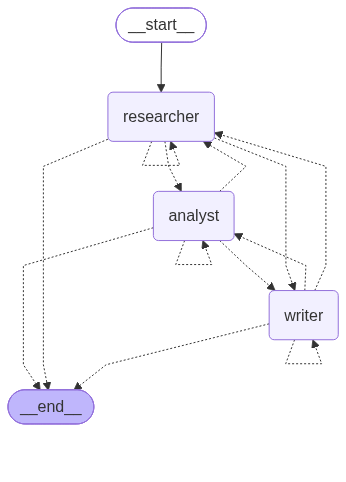

In [ ]:
# ---------- Cell 6: Build the swarm graph ----------

def build_swarm_graph():
    """Wire the three agent nodes into a runnable LangGraph app.

    Notice what is MISSING: there are no edges between the agents.
    Each node returns Command(goto=...), so the agents decide the next step at runtime.
    The only edge we define is the entry point: START -> researcher.
    """
    graph = StateGraph(SwarmState)

    # Register one node per agent (the node functions were built in Cell 5).
    for name, node_fn in AGENT_NODES.items():
        graph.add_node(name, node_fn)

    # The task always enters the swarm at the researcher.
    graph.add_edge(START, "researcher")

    return graph.compile()


def show_graph(app) -> None:
    """Render the graph as an image; print Mermaid source if rendering fails (e.g. offline)."""
    try:
        from IPython.display import Image, display
        display(Image(app.get_graph().draw_mermaid_png()))
    except Exception:
        print(app.get_graph().draw_mermaid())


swarm_app = build_swarm_graph()
show_graph(swarm_app)

In [ ]:
# ---------- Cell 7: Run the swarm on the tricky task ----------

import time

# Same task as the supervisor demo: Zephyr S2 is DISCONTINUED (replaced by S2 Plus).
TRICKY_TASK = (
    "Compare Zephyr S1 and Zephyr S2: find the price and range of both, calculate the price per km "
    "of range for each, and write a short buying recommendation."
)


def run_swarm(task: str, label: str) -> dict:
    """Run the swarm once and report the metrics we compare in Part 6 (calls, time, handoffs)."""
    STATS.reset()
    start = time.perf_counter()

    # recursion_limit = LangGraph's own hard stop on graph steps (a second safety net
    # next to our max_handoffs cap).
    state = swarm_app.invoke(new_swarm_state(task), config={"recursion_limit": 40})

    result = {
        "final": state["final"],
        "llm_calls": STATS.llm_calls,
        "handoffs": state["handoffs"],
        "seconds": round(time.perf_counter() - start, 1),
    }
    print(f"\n📊 {label}: {result['llm_calls']} LLM calls, "
          f"{result['handoffs']} handoffs, {result['seconds']}s")
    return result


CFG.verbose = True   # show the full trace
swarm_tricky = run_swarm(TRICKY_TASK, "Swarm | tricky task")


📝 [researcher] takes over. Latest message:
Compare Zephyr S1 and Zephyr S2: find the price and range of both, calculate the price per km of range for each, and write a short buying recommendation.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S1'}

📥 `search_catalog` returned: Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S2'}

📥 `search_catalog` returned: Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S2 Plus'}

📥 `search_catalog` returned: Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.

🔀 [researcher] -> [analyst]
Gathered product data:
- Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.
- Zephyr S2: DISCONTINUED, replaced by Zephyr S2 Plus.
- Zephyr S2 Plus (replacement for S2): price 91000 INR, range 130 km, warranty 2 years.
Next step: Analyst should calculate price per km of range f

In [ ]:
# ---------- Cell 8: Score the swarm with an LLM judge ----------

import json
import pandas as pd

# JSON-mode model, used only for the judge (the standalone swarm notebook didn't need it before).
llm_json = ChatGroq(
    api_key=API_KEY,
    model=CFG.model,
    temperature=0,
    model_kwargs={"response_format": {"type": "json_object"}},
)

# A task with NO surprise, so we can compare the swarm's cost on easy vs. tricky input.
SIMPLE_TASK = (
    "Find the price and range of Zephyr S1 and Zephyr S2 Plus, calculate the price per km of range "
    "for each, and write a short buying recommendation."
)

# Quiet run: no trace, just the metrics.
CFG.verbose = False
swarm_simple = run_swarm(SIMPLE_TASK, "Swarm | simple task")
CFG.verbose = True

# swarm_tricky comes from Cell 7.
SWARM_RESULTS = {
    "Swarm | simple task": swarm_simple,
    "Swarm | tricky task": swarm_tricky,
}

# ---------- The judge: same reference facts and rubric as the supervisor notebook ----------
REFERENCE = (
    "Zephyr S1: 60000 INR, 100 km range -> 600 INR per km. "
    "Zephyr S2 is DISCONTINUED and replaced by Zephyr S2 Plus: 91000 INR, 130 km range -> 700 INR per km. "
    "Correct recommendation: Zephyr S1 is better value per km of range."
)

JUDGE_PROMPT = (
    "You are a strict judge. Compare the answer with the reference facts and score it 1-10. "
    "10 = correct numbers, covers both scooters (S2 replaced by S2 Plus), clear recommendation. "
    "Give a LOW score if it invents data, skips a product, or says data is missing that could have been found.\n"
    'Reply ONLY with JSON: {"score": number, "reason": "one short sentence"}'
)


def judge(answer: str) -> dict:
    """Ask the judge to score one final answer against the reference facts."""
    reply = call_llm(
        [SystemMessage(JUDGE_PROMPT),
         HumanMessage(f"Reference facts:\n{REFERENCE}\n\nAnswer to judge:\n{answer}")],
        llm_json,
    )
    return json.loads(reply.content)


rows = []
for label, run in SWARM_RESULTS.items():
    verdict = judge(run["final"])
    rows.append({
        "Run": label,
        "LLM calls": run["llm_calls"],
        "Handoffs": run["handoffs"],
        "Time (s)": run["seconds"],
        "Quality (1-10)": verdict["score"],
        "Judge reason": verdict["reason"],
    })

pd.set_option("display.max_colwidth", 120)
swarm_df = pd.DataFrame(rows)
swarm_df


📊 Swarm | simple task: 7 LLM calls, 2 handoffs, 4.7s


,Run,LLM calls,Handoffs,Time (s),Quality (1-10),Judge reason
0,Swarm | simple task,7,2,4.7,10,"Accurately lists both models, correct per‑km values, and recommends S1 as better value"
1,Swarm | tricky task,8,2,4.4,10,"Accurately presents both models, correct values, and proper recommendation"


In [ ]:
# ---------- Cell 9 (optional): Fix the missing "S2 was replaced" note, then re-run ----------

# Root cause: in a swarm there is no supervisor to merge everything at the end, so the
# information must travel inside the handoff summaries. Two small prompt additions fix this:
#   1. The analyst must keep discontinued/replacement notes in its handoff summary.
#   2. The writer must mention such notes in its final answer.
#
# No need to rebuild the graph: the agent nodes look up AGENT_PROMPTS at run time,
# so editing the dictionary is enough.

AGENT_PROMPTS["analyst"] += (
    " In your handoff summary, ALWAYS keep any note about a discontinued product and its "
    "replacement, together with the numbers."
)

AGENT_PROMPTS["writer"] += (
    " If the facts say a product was discontinued and replaced, state that clearly in one "
    "sentence before your recommendation."
)

# Re-run the tricky task with the improved prompts (full trace).
CFG.verbose = True
swarm_tricky_v2 = run_swarm(TRICKY_TASK, "Swarm v2 | tricky task")

# Score the new answer with the same judge from Cell 8 and compare with the earlier run.
before = judge(swarm_tricky["final"])
after = judge(swarm_tricky_v2["final"])

comparison = pd.DataFrame([
    {"Run": "Swarm v1 | tricky task", "LLM calls": swarm_tricky["llm_calls"],
     "Quality (1-10)": before["score"], "Judge reason": before["reason"]},
    {"Run": "Swarm v2 | tricky task", "LLM calls": swarm_tricky_v2["llm_calls"],
     "Quality (1-10)": after["score"], "Judge reason": after["reason"]},
])
comparison


📝 [researcher] takes over. Latest message:
Compare Zephyr S1 and Zephyr S2: find the price and range of both, calculate the price per km of range for each, and write a short buying recommendation.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S1'}

📥 `search_catalog` returned: Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S2'}

📥 `search_catalog` returned: Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.

🔧 [researcher] calls `search_catalog` with {'query': 'Zephyr S2 Plus'}

📥 `search_catalog` returned: Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.

🔀 [researcher] -> [analyst]
Gathered product data:
- Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.
- Zephyr S2 is DISCONTINUED; replacement is Zephyr S2 Plus.
- Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.
Next step: Calculate the price per km of range for Zephyr S1 and Zephyr S2 

,Run,LLM calls,Quality (1-10),Judge reason
0,Swarm v1 | tricky task,8,10,"Accurately presents both models, correct values, and proper recommendation"
1,Swarm v2 | tricky task,8,10,"Accurately presents both models, correct calculations, and proper recommendation"


In [ ]:
# ---------- Cell 10 (optional): Supervisor vs. swarm side by side ----------

# STEP 1: Fill in the supervisor numbers by hand, copied from Part 6 of the first
# notebook (its `df` table). The values below are PLACEHOLDERS (None) on purpose:
# I have not run that notebook, so I won't invent numbers for you.
SUPERVISOR_ROWS = [
    {"Pattern": "Static supervisor",  "Task": "tricky", "LLM calls": None, "Time (s)": None, "Quality": None},
    {"Pattern": "Dynamic supervisor", "Task": "tricky", "LLM calls": None, "Time (s)": None, "Quality": None},
]

# STEP 2: Swarm numbers come straight from this notebook (Cells 7, 8 and 9).
SWARM_ROWS = [
    {"Pattern": "Swarm v1", "Task": "tricky", "LLM calls": swarm_tricky["llm_calls"],
     "Time (s)": swarm_tricky["seconds"], "Quality": before["score"]},
    {"Pattern": "Swarm v2", "Task": "tricky", "LLM calls": swarm_tricky_v2["llm_calls"],
     "Time (s)": swarm_tricky_v2["seconds"], "Quality": after["score"]},
]

display(pd.DataFrame(SUPERVISOR_ROWS + SWARM_ROWS))

,Pattern,Task,LLM calls,Time (s),Quality
0,Static supervisor,tricky,NaN,NaN,NaN
1,Dynamic supervisor,tricky,NaN,NaN,NaN
2,Swarm v1,tricky,8.0,4.4,10.0
3,Swarm v2,tricky,8.0,7.4,10.0


# Hierarchical Agents

# 🏢 Hierarchical Agents — CEO → Directors → Workers
**LangGraph + Groq** · built to match the tree from your notes

**What it is:** multiple *layers of supervision*. A top-level supervisor manages mid-level supervisors, and each of those manages its own team of workers. The hierarchy can be as deep as needed.

**When a flat supervisor isn't enough:** a single supervisor managing ~10 workers starts to lose coherence — its context fills with all their outputs and the synthesis quality degrades. Hierarchical agents scale to bigger tasks by adding management layers.

```
CEO Agent (top-level supervisor)
├── Research Director Agent
│     ├── Market Research Worker
│     ├── Competitor Analysis Worker
│     └── Academic Literature Worker
├── Analysis Director Agent
│     ├── Financial Analysis Worker
│     └── Data Synthesis Worker
└── Production Director Agent
      ├── Writing Worker
      └── Editing Worker
```

| Name in the tree | Key in the code | Its tool |
|---|---|---|
| Market Research Worker | `market_research_worker` | `search_market_data` |
| Competitor Analysis Worker | `competitor_analysis_worker` | `search_competitors` |
| Academic Literature Worker | `academic_literature_worker` | `search_papers` |
| Financial Analysis Worker | `financial_analysis_worker` | `calculator` |
| Data Synthesis Worker | `data_synthesis_worker` | – |
| Writing Worker | `writing_worker` | – |
| Editing Worker | `editing_worker` | – |

**Where hierarchy adds genuine value:** tasks with *natural domain phases* (research → analyse → draft → review). A simple "search and summarise" task doesn't need it.

### 🛴 The running example
> *"Should we launch our electric scooter in Pune?"* — every worker in the tree has a real job: market size, competitors, research on charging infrastructure, break-even maths, a synthesis, a draft and an edit.
>
> 🎯 **Planted surprise:** competitor `Zephyr S2` is **discontinued** and replaced by `Zephyr S2 Plus`. Does that fact survive the trip up and down all three layers?
>
> *All data in this notebook is made up for the demo (including the "studies").*

**Trace legend** — indentation shows the level: CEO = none, Director = 1, Worker = 2

| Icon | Meaning |
|---|---|
| 🧠 | A supervisor (CEO / Director) **thinking** |
| 📋 | A **delegation** decision / goal handed down |
| 📝 | The **task** a worker received |
| 🔧 / 📥 | **Tool call** / **tool result** |
| 🤖 | A worker's **answer** |
| 📤 | A Director's **report going UP** to the CEO |
| ✅ | **Final answer** |

**Cells:** 1 Install + key · 2 Setup · 3 Tools · 4 Workers · 5 Directors · 6 CEO + graph · 7 Run · 8 Judge the answer · 9 (optional) vs. a flat supervisor

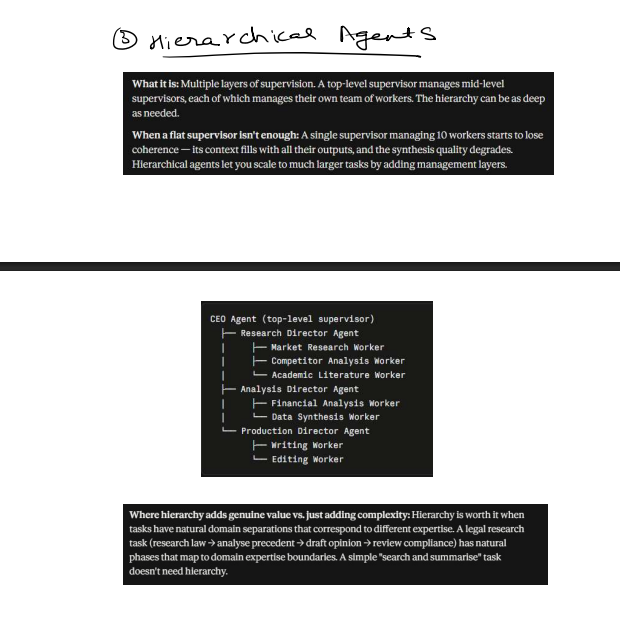

In [ ]:
from IPython.display import display, Image
import os

# Find the image in Google Colab
image_path = "/content/Hierarchical Agents notes SS.png"

# Display the image
if os.path.exists(image_path):
    display(Image(filename=image_path))
else:
    print("Image not found. Check the file name and path.")

In [ ]:
# ---------- Cell 1: Install libraries + load the Groq API key ----------

# langgraph       -> graph, state and routing (CEO -> Directors -> Workers)
# langchain-groq  -> Groq chat model
# langchain-core  -> message and tool primitives
# pandas          -> the optional comparison table in Cell 9

%pip install -q langgraph langchain-groq langchain-core pandas

import os
from getpass import getpass


def load_api_key(secret_name: str = "groq_api3") -> str:
    """Return the Groq API key from Colab Secrets, the environment, or a prompt."""
    try:
        from google.colab import userdata   # only available inside Colab
        return userdata.get(secret_name)
    except Exception:
        pass                                # Secret missing -> try next option

    return os.environ.get(secret_name) or getpass(
        f"Enter {secret_name}: "
    )


# Load the API key from the Colab Secret named "groq_api"
API_KEY = load_api_key()

# Check whether the API key was loaded successfully
print("API key loaded:", bool(API_KEY))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 827.0 kB/s eta 0:00:00
API key loaded: True


In [ ]:
# ---------- Cell 2: Imports, configuration, LLM and helpers ----------

import json
import textwrap
import threading
import time
from dataclasses import dataclass
from typing import TypedDict

import pandas as pd
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.graph import END, START, StateGraph


# ---------- Configuration: all tunable settings in one place ----------
@dataclass
class Config:
    model: str = "openai/gpt-oss-120b"   # Groq model that supports tool calling
    verbose: bool = True                 # print the agent trace?
    max_worker_steps: int = 5            # max tool-calling rounds inside ONE worker
    max_director_steps: int = 5          # max decisions per Director (3 workers + FINISH + 1 spare)
    max_ceo_steps: int = 4               # max Directors the CEO may call (loop safety)


CFG = Config()


# ---------- Models ----------
# Plain text model (workers) and a JSON-mode model (CEO / Directors make structured decisions).
llm = ChatGroq(api_key=API_KEY, model=CFG.model, temperature=0)
llm_json = ChatGroq(
    api_key=API_KEY,
    model=CFG.model,
    temperature=0,
    model_kwargs={"response_format": {"type": "json_object"}},
)


# ---------- LLM call counter (a proxy for cost) ----------
class LLMStats:
    """Thread-safe counter of LLM calls."""

    def __init__(self) -> None:
        self._lock = threading.Lock()
        self.llm_calls = 0

    def increment(self) -> None:
        with self._lock:
            self.llm_calls += 1

    def reset(self) -> None:
        with self._lock:
            self.llm_calls = 0


STATS = LLMStats()


def call_llm(messages, model=None):
    """Every LLM call goes through here, so it is always counted."""
    STATS.increment()
    return (model or llm).invoke(messages)


def ask_json(system: str, user: str, retries: int = 3) -> dict:
    """Ask the JSON-mode model and return a dict. Retries on empty/invalid JSON."""
    last_error = None
    for attempt in range(retries):
        nudge = "" if attempt == 0 else "\n\n(Reply with ONE valid JSON object only.)"
        try:
            reply = call_llm([SystemMessage(system), HumanMessage(user + nudge)], llm_json)
            return json.loads(reply.content)
        except Exception as exc:
            retryable = isinstance(exc, json.JSONDecodeError) or "json_validate_failed" in str(exc)
            if not retryable:
                raise                      # a different error (auth, rate limit...): do not hide it
            last_error = exc
            if CFG.verbose:
                print(f"⚠️ JSON reply failed (attempt {attempt + 1}/{retries}), retrying...")
            time.sleep(1.5)
    raise RuntimeError(f"Model returned no valid JSON after {retries} attempts.") from last_error


# ---------- Tracing (indented by hierarchy level) ----------
ICONS = {
    "think": "🧠",        # a supervisor (CEO or Director) reasoning
    "plan": "📋",         # a delegation decision
    "prompt": "📝",       # a task handed down to a worker
    "tool_call": "🔧",
    "tool_result": "📥",
    "output": "🤖",       # a worker's answer
    "report": "📤",       # a Director's report going UP to the CEO
    "final": "✅",
}


def show(kind: str, text: str, level: int = 0) -> None:
    """Print one trace line. level: 0 = CEO, 1 = Director, 2 = Worker (more indent = lower in the tree)."""
    if CFG.verbose:
        print(textwrap.indent(f"\n{ICONS[kind]} {text}", "      " * level))


# ---------- Smoke test ----------
print("Smoke test:", llm.invoke("Reply with exactly three words: connection is working").content)
show("think", "CEO-level line (no indent)", level=0)
show("plan", "Director-level line (indented once)", level=1)
show("output", "Worker-level line (indented twice)", level=2)

Smoke test: connection is working

🧠 CEO-level line (no indent)

      📋 Director-level line (indented once)

            🤖 Worker-level line (indented twice)


In [ ]:
# ---------- Cell 3: Tools the workers can use ----------

import ast
import operator

# ---------- Fake data sources (in a real project: databases, web search, paper APIs) ----------
MARKET_DATA = {
    "pune": "Pune e-scooter market: about 45000 units sold per year, growing 20 percent per year. "
            "Typical buyer budget: 80000 to 95000 INR.",
}

COMPETITORS = {
    "zephyr s1":      "Zephyr S1: price 60000 INR, range 100 km, warranty 3 years.",
    "zephyr s2":      "Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.",   # <- the surprise
    "zephyr s2 plus": "Zephyr S2 Plus: price 91000 INR, range 130 km, warranty 2 years.",
}

PAPERS = {
    "charging": "Demo study A (fictional): every extra public charging point per 1000 residents raises "
                "e-scooter adoption by about 4 percent. Pune has about 0.8 charging points per 1000 residents.",
    "subsidy":  "Demo study B (fictional): a 10 percent state purchase subsidy raises first-year e-scooter "
                "sales by about 15 percent.",
}


def lookup(table: dict, query: str) -> str:
    """Find the entry whose key appears in the query (longest keys first)."""
    key = query.lower().strip()
    for name in sorted(table, key=len, reverse=True):
        if name in key:
            return table[name]
    return "No information found."


@tool
def search_market_data(query: str) -> str:
    """Search market data (size, growth, buyer budget) for a city. Input: a city name such as 'Pune'."""
    return lookup(MARKET_DATA, query)


@tool
def search_competitors(query: str) -> str:
    """Search competitor products for price, range and warranty. Input: a product name such as 'Zephyr S1'."""
    return lookup(COMPETITORS, query)


@tool
def search_papers(query: str) -> str:
    """Search research findings on a topic. Input: a topic such as 'charging' or 'subsidy'."""
    return lookup(PAPERS, query)


# ---------- Safe calculator ----------
_ALLOWED_OPS = {
    ast.Add: operator.add, ast.Sub: operator.sub,
    ast.Mult: operator.mul, ast.Div: operator.truediv,
    ast.USub: operator.neg, ast.UAdd: operator.pos,
}


def _safe_eval(node):
    """Recursively evaluate an AST that contains only numbers and + - * /."""
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("unsupported expression")


@tool
def calculator(expression: str) -> str:
    """Evaluate an arithmetic expression such as '20000000/(85000-65000)'. Allowed: numbers and + - * / ( )."""
    try:
        result = _safe_eval(ast.parse(expression.strip(), mode="eval"))
        return f"{result:.2f}".rstrip("0").rstrip(".")   # 1000.00 -> "1000"
    except ZeroDivisionError:
        return "Error: division by zero."
    except (ValueError, SyntaxError):
        return "Error: only numbers and + - * / ( ) are allowed."


# ---------- Quick tests (no LLM involved) ----------
print(search_market_data.invoke({"query": "Pune"}))
print(search_competitors.invoke({"query": "Zephyr S2"}))                    # the discontinued one
print(search_papers.invoke({"query": "charging infrastructure"}))
print(calculator.invoke({"expression": "20000000/(85000-65000)"}))          # break-even units
print(calculator.invoke({"expression": "1000/45000*100"}))                  # market share needed (%)
print(calculator.invoke({"expression": "__import__('os').system('ls')"}))   # must be rejected

Pune e-scooter market: about 45000 units sold per year, growing 20 percent per year. Typical buyer budget: 80000 to 95000 INR.
Zephyr S2: DISCONTINUED. It has been replaced by Zephyr S2 Plus.
Demo study A (fictional): every extra public charging point per 1000 residents raises e-scooter adoption by about 4 percent. Pune has about 0.8 charging points per 1000 residents.
1000
2.22
Error: only numbers and + - * / ( ) are allowed.


In [ ]:
# ---------- Cell 4: The seven specialist workers ----------

#   Research team   -> market_research_worker, competitor_analysis_worker, academic_literature_worker
#   Analysis team   -> financial_analysis_worker, data_synthesis_worker
#   Production team -> writing_worker, editing_worker

WORKERS = {
    "market_research_worker": {
        "prompt": (
            "You are a market research worker. Use the search_market_data tool to look up the market of the "
            "city named in your task (one search per city). Report exactly what the tool returned."
        ),
        "tools": [search_market_data],
    },
    "competitor_analysis_worker": {
        "prompt": (
            "You are a competitor analysis worker. Use the search_competitors tool to look up ONLY the "
            "competitor products named in your task (one search per product). If a product is DISCONTINUED "
            "and a replacement is named, also look up the replacement. Report exactly what the tool returned."
        ),
        "tools": [search_competitors],
    },
    "academic_literature_worker": {
        "prompt": (
            "You are an academic literature worker. Use the search_papers tool to find research findings on "
            "the topics named in your task (for example 'charging' or 'subsidy'; one search per topic). "
            "Report the findings exactly as returned. Never invent studies."
        ),
        "tools": [search_papers],
    },
    "financial_analysis_worker": {
        "prompt": (
            "You are a financial analysis worker. Use the calculator tool for EVERY calculation. "
            "Formulas: break-even units = fixed cost / (price - variable cost per unit); "
            "market share needed (%) = break-even units / yearly market units * 100. "
            "Use only the numbers you are given. If a number is missing, say so - never invent data."
        ),
        "tools": [calculator],
    },
    "data_synthesis_worker": {
        "prompt": (
            "You are a data synthesis worker. Merge the market facts, competitor facts, research findings "
            "and financial results you are given into one compact summary (a few short lines per topic). "
            "Keep every number exactly as given, keep any 'discontinued / replaced by' note, and never add "
            "information that is not in the input."
        ),
        "tools": [],
    },
    "writing_worker": {
        "prompt": (
            "You are a writing worker. Write a short launch recommendation (go / no-go, 2-3 reasons and one "
            "risk) using ONLY the facts you are given. If a competitor product was discontinued and replaced, "
            "state that in one sentence. If some information is missing, say so honestly."
        ),
        "tools": [],
    },
    "editing_worker": {
        "prompt": (
            "You are an editing worker. Check the draft against the facts you are given. Fix any wrong number, "
            "unsupported claim or missing 'discontinued / replaced' note, and keep the text short. "
            "Return ONLY the final polished text, with no comments about your edits."
        ),
        "tools": [],
    },
}


def run_worker(name: str, task: str, level: int = 2) -> str:
    """Run one worker on one task and return its final text answer."""
    if name not in WORKERS:
        return f"Error: unknown worker '{name}'."

    cfg = WORKERS[name]
    tools_by_name = {t.name: t for t in cfg["tools"]}
    model = llm.bind_tools(cfg["tools"]) if cfg["tools"] else llm   # tell the LLM which tools it may call

    messages = [SystemMessage(cfg["prompt"]), HumanMessage(task)]
    show("prompt", f"[{name}] received task:\n{task}", level)

    for _ in range(CFG.max_worker_steps):
        ai_message = call_llm(messages, model)
        messages.append(ai_message)

        # No tool requested -> this is the worker's final answer.
        if not ai_message.tool_calls:
            show("output", f"[{name}] answer:\n{ai_message.content}", level)
            return ai_message.content

        # Tool(s) requested -> run each one and feed the result back to the model.
        for call in ai_message.tool_calls:
            show("tool_call", f"[{name}] calls `{call['name']}` with {call['args']}", level)
            try:
                result = tools_by_name[call["name"]].invoke(call["args"])
            except Exception as exc:   # report tool errors to the model instead of crashing
                result = f"Tool error: {exc}"
            show("tool_result", f"`{call['name']}` returned: {result}", level)
            messages.append(ToolMessage(content=str(result), tool_call_id=call["id"]))

    return "Stopped: too many tool-calling steps."


# ---------- Quick test: one worker on its own (uses the LLM) ----------
_ = run_worker("market_research_worker", "Find the yearly size and growth of the Pune e-scooter market.")


            📝 [market_research_worker] received task:
            Find the yearly size and growth of the Pune e-scooter market.

            🔧 [market_research_worker] calls `search_market_data` with {'query': 'Pune e-scooter market size yearly growth'}

            📥 `search_market_data` returned: Pune e-scooter market: about 45000 units sold per year, growing 20 percent per year. Typical buyer budget: 80000 to 95000 INR.

            🤖 [market_research_worker] answer:
            Pune e-scooter market: about 45,000 units sold per year, growing 20 percent per year. Typical buyer budget: 80,000 to 95,000 INR.


In [ ]:
# ---------- Cell 5: The three Directors ----------

# What each worker does. A Director reads this to know whom it can delegate to.
WORKER_INFO = {
    "market_research_worker":     "finds market size, growth and buyer budget for a city",
    "competitor_analysis_worker": "finds price, range and warranty of competitor products",
    "academic_literature_worker": "finds research findings (charging infrastructure, subsidies)",
    "financial_analysis_worker":  "calculates break-even units and market share needed with a calculator",
    "data_synthesis_worker":      "merges all facts and results into one compact summary",
    "writing_worker":             "writes the launch recommendation from the given facts",
    "editing_worker":             "checks the draft against the facts and returns the polished final text",
}

# The org chart: Director -> its team. `role` is what the CEO sees (the CEO never sees the workers).
DIRECTORS = {
    "research_director": {
        "title": "Research Director",
        "role": "researches the city market, the competitors and academic findings",
        "workers": ["market_research_worker", "competitor_analysis_worker", "academic_literature_worker"],
    },
    "analysis_director": {
        "title": "Analysis Director",
        "role": "calculates break-even units and market share needed, and merges all findings into one summary",
        "workers": ["financial_analysis_worker", "data_synthesis_worker"],
    },
    "production_director": {
        "title": "Production Director",
        "role": "writes and edits the final launch recommendation",
        "workers": ["writing_worker", "editing_worker"],
    },
}


def format_results(steps: list) -> str:
    return "\n".join(f"- ({s['worker']}) {s['result']}" for s in steps)


def build_director_prompt(name: str) -> str:
    """System prompt for one Director: its team, its rules and the JSON reply format."""
    cfg = DIRECTORS[name]
    team = "\n".join(f"- {w}: {WORKER_INFO[w]}" for w in cfg["workers"])
    return (
        f"You are the {cfg['title']}, a mid-level supervisor. You manage ONLY these workers:\n{team}\n"
        "You receive a goal from the CEO. Decide ONLY the NEXT single step.\n"
        "Rules:\n"
        "- EVERY subtask must name things explicitly: the city (for example 'Pune'), the competitor names "
        "(for example 'Zephyr S1' and 'Zephyr S2') and any numbers the worker needs. Never write vague "
        "words like 'the market' or 'the competitors'.\n"
        "- Read the results carefully. If something unexpected happened (product discontinued, data "
        "missing), adapt your plan, for example by also covering the replacement product.\n"
        "- If a worker says it lacks information or asks a question, do NOT accept that as a result: "
        "give the same worker the subtask again, this time with the exact names and numbers.\n"
        "- Workers cannot talk to each other; you pass information between them.\n"
        "- Answer FINISH when your team's results fully cover the goal. Then write `report`: a compact "
        "summary for the CEO that keeps every number and every 'discontinued / replaced by' note exactly "
        "as found. If your team produced a final text, put that COMPLETE text in the report.\n"
        'Reply ONLY with JSON: {"thought": "your reasoning", "next": "<worker name or FINISH>", '
        '"subtask": "what that worker should do (empty if FINISH)", '
        '"report": "summary for the CEO (empty unless FINISH)"}'
    )


def build_worker_task(subtask: str, context: str, steps: list) -> str:
    """Assemble a worker's prompt. The Director is the messenger for ALL context."""
    parts = [subtask]
    if context:
        parts.append("Context (original task and other teams' reports):\n" + context)
    if steps:
        parts.append("Results from your team so far:\n" + format_results(steps))
    return "\n\n".join(parts)


def run_director(name: str, goal: str, context: str = "") -> dict:
    """Run one Director's mini supervisor loop and return its report for the CEO.

    Loop: decide next worker -> run worker -> decide again ... -> FINISH (with report).
    Returns {"report": str, "steps": list}.
    """
    cfg = DIRECTORS[name]
    system = build_director_prompt(name)
    steps: list = []
    report = ""

    show("plan", f"[{cfg['title']}] received goal from CEO:\n{goal}", level=1)

    for _ in range(CFG.max_director_steps):      # loop safety for this level
        done = format_results(steps) or "(nothing done yet)"
        user = f"Goal from CEO: {goal}\n\n"
        if context:
            user += f"Context from CEO (original task and other teams' reports):\n{context}\n\n"
        user += f"Results of your team so far:\n{done}"

        out = ask_json(system, user)
        nxt = out.get("next", "FINISH")
        if nxt != "FINISH" and nxt not in cfg["workers"]:   # guard: a Director can only call ITS workers
            nxt = "FINISH"

        show("think", f"[{cfg['title']}] THOUGHT: {out.get('thought', '')}", level=1)

        if nxt == "FINISH":
            report = out.get("report", "")
            break

        subtask = out.get("subtask", "")
        show("plan", f"[{cfg['title']}] -> {nxt}: {subtask}", level=1)
        result = run_worker(nxt, build_worker_task(subtask, context, steps), level=2)
        steps.append({"worker": nxt, "task": subtask, "result": result})

    # Fallback: step cap reached or no report written -> use the raw results.
    if not report:
        report = format_results(steps) or "No results."

    show("report", f"[{cfg['title']}] REPORT to CEO:\n{report}", level=1)
    return {"report": report, "steps": steps}


# ---------- Quick test: one Director on its own (uses the LLM) ----------
STATS.reset()
test = run_director(
    "research_director",
    "Research the Pune market, the competitors Zephyr S1 and Zephyr S2, and findings on charging infrastructure.",
    context="Original user task: Should we launch our electric scooter in Pune?",
)
print(f"\n📊 Research Director alone: {STATS.llm_calls} LLM calls, {len(test['steps'])} worker runs")


      📋 [Research Director] received goal from CEO:
      Research the Pune market, the competitors Zephyr S1 and Zephyr S2, and findings on charging infrastructure.

      🧠 [Research Director] THOUGHT: We need to gather data for all three aspects. Start by obtaining market size, growth, and buyer budget for Pune to inform the launch decision.

      📋 [Research Director] -> market_research_worker: Find the market size (in units sold per year), annual growth rate (percentage), and average buyer budget (in INR) for electric scooters in Pune.

            📝 [market_research_worker] received task:
            Find the market size (in units sold per year), annual growth rate (percentage), and average buyer budget (in INR) for electric scooters in Pune.

            Context (original task and other teams' reports):
            Original user task: Should we launch our electric scooter in Pune?

            🔧 [market_research_worker] calls `search_market_data` with {'query': 'Pune electric 

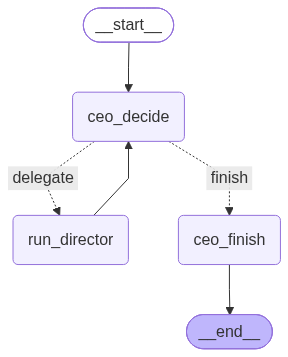

In [ ]:
# ---------- Cell 6: CEO + the full hierarchical graph ----------

class HState(TypedDict):
    """Shared state of the hierarchy. It holds Director REPORTS, never raw worker outputs."""
    task: str            # the user's original request
    steps: list          # [{"director", "goal", "report"}, ...] one entry per Director run
    next_director: str   # which Director goes next (or "FINISH")
    next_goal: str       # the goal the CEO gives that Director
    final: str           # final answer for the user


def new_hstate(task: str) -> dict:
    return {"task": task, "steps": [], "next_director": "", "next_goal": "", "final": ""}


def format_reports(steps: list) -> str:
    return "\n".join(f"- ({DIRECTORS[s['director']]['title']}) {s['report']}" for s in steps)


def build_ceo_prompt() -> str:
    # The CEO sees only each Director's ROLE, not the workers underneath.
    team = "\n".join(f"- {name}: {cfg['role']}" for name, cfg in DIRECTORS.items())
    return (
        "You are the CEO agent, the top-level supervisor. You manage ONLY these Directors:\n"
        f"{team}\n"
        "Look at the task and the Directors' reports so far, then decide ONLY the NEXT single step.\n"
        "Rules:\n"
        "- Order: research_director (facts) -> analysis_director (calculations + synthesis) -> "
        "production_director (final text).\n"
        "- EVERY goal must name things explicitly: the city, the competitor names and the numbers from the "
        "user's task that the Director needs. Never write vague words like 'the market' or 'the competitors'.\n"
        "- Include the key facts from earlier reports in the next goal.\n"
        "- Read reports carefully. If something unexpected happened (a competitor discontinued and "
        "replaced), make sure the next goals cover the replacement too.\n"
        "- The goal for production_director must say: its report must contain the COMPLETE final "
        "launch recommendation text, not a summary of it.\n"
        "- Answer FINISH only after production_director has delivered the final recommendation.\n"
        'Reply ONLY with JSON: {"thought": "your reasoning", "next": "<director name or FINISH>", '
        '"goal": "goal for that Director (empty if FINISH)"}'
    )


CEO_PROMPT = build_ceo_prompt()


def ceo_context_for(state: HState) -> str:
    """What the CEO hands down to a Director: the original task + earlier Director reports."""
    context = f"Original user task (use the exact names and numbers from it): {state['task']}"
    if state["steps"]:
        context += "\n\nReports from other teams:\n" + format_reports(state["steps"])
    return context


# ---------- Node 1: the CEO decides which Director goes next ----------
def ceo_decide(state: HState) -> dict:
    done = format_reports(state["steps"]) or "(nothing done yet)"
    out = ask_json(CEO_PROMPT, f"Task: {state['task']}\n\nDirector reports so far:\n{done}")

    nxt = out.get("next", "FINISH")
    if nxt != "FINISH" and nxt not in DIRECTORS:    # guard: the CEO can only call Directors
        nxt = "FINISH"
    if len(state["steps"]) >= CFG.max_ceo_steps:    # guard: loop safety for the top level
        nxt = "FINISH"

    show("think", f"[CEO] THOUGHT: {out.get('thought', '')}", level=0)
    show("plan", f"[CEO] NEXT -> {nxt}: {out.get('goal', '')}", level=0)
    return {"next_director": nxt, "next_goal": out.get("goal", "")}


# ---------- Node 2: run the chosen Director (which runs its own workers) ----------
def run_director_node(state: HState) -> dict:
    result = run_director(state["next_director"], state["next_goal"], context=ceo_context_for(state))
    step = {"director": state["next_director"], "goal": state["next_goal"], "report": result["report"]}
    return {"steps": state["steps"] + [step]}


def route_after_ceo(state: HState) -> str:
    """Routing function for the conditional edge."""
    return "finish" if state["next_director"] == "FINISH" else "delegate"


# ---------- Node 3: the CEO writes the final answer ----------
def ceo_finish(state: HState) -> dict:
    reply = call_llm([
        SystemMessage(
            "You are the CEO. Turn the Directors' reports into ONE clear final answer for the user. "
            "Use only facts from the reports, and keep any 'discontinued / replaced' note."
        ),
        HumanMessage(f"User task: {state['task']}\n\nDirector reports:\n{format_reports(state['steps'])}"),
    ])
    show("final", "FINAL ANSWER:\n" + reply.content, level=0)
    return {"final": reply.content}


# ---------- Build the graph ----------
def build_hierarchy_graph():
    graph = StateGraph(HState)
    graph.add_node("ceo_decide", ceo_decide)
    graph.add_node("run_director", run_director_node)
    graph.add_node("ceo_finish", ceo_finish)

    graph.add_edge(START, "ceo_decide")
    graph.add_conditional_edges(
        "ceo_decide", route_after_ceo, {"delegate": "run_director", "finish": "ceo_finish"}
    )
    graph.add_edge("run_director", "ceo_decide")   # the loop: the report goes back UP to the CEO
    graph.add_edge("ceo_finish", END)
    return graph.compile()


def show_graph(app) -> None:
    """Render the graph as an image; print Mermaid source if rendering fails (e.g. offline)."""
    try:
        from IPython.display import Image, display
        display(Image(app.get_graph().draw_mermaid_png()))
    except Exception:
        print(app.get_graph().draw_mermaid())


hierarchy_app = build_hierarchy_graph()
show_graph(hierarchy_app)

In [ ]:
# ---------- Cell 6b: Fix for the Cell 7 error (run AFTER Cell 6, BEFORE Cell 7) ----------

# What the trace and the error showed:
#   1. RateLimitError: Groq's free tier allows 8000 tokens per MINUTE. We were over by a hair
#      (5949 used + 2071 requested) and the message even said "try again in 150ms".
#      -> call_llm now waits and retries by itself.
#   2. The REAL problem was behind it: the Research Director never called academic_literature_worker.
#      The CEO asked for data no tool has (price sensitivity, charger counts, market share...), the
#      Director kept re-asking the same workers, ran out of steps, and then dumped ALL raw worker
#      text as its "report". That huge report was copied into every later prompt -> too many tokens.
#      -> workers answer briefly, Directors never re-run a worker while others are unused,
#         accept "not available", and always write a COMPACT report (forced if steps run out).
#
# These definitions REPLACE the old ones (looked up by name at run time), so Cells 2-6 need no re-run.

import re


# ---------- FIX 1: call_llm waits and retries on Groq rate limits ----------
def _wait_seconds(message: str, attempt: int) -> float:
    """Read 'try again in 150ms / 2.5s' from Groq's message; otherwise back off exponentially."""
    match = re.search(r"try again in ([0-9.]+)(ms|s)", message)
    if match:
        value = float(match.group(1))
        seconds = value / 1000 if match.group(2) == "ms" else value
        return min(seconds + 1.0, 60.0)          # +1s safety margin
    return min(2.0 ** attempt, 30.0)


def call_llm(messages, model=None, max_retries: int = 8):
    """Every LLM call goes through here. Counted once, even if it needed retries."""
    STATS.increment()
    for attempt in range(max_retries):
        try:
            return (model or llm).invoke(messages)
        except Exception as exc:
            text = str(exc)
            is_rate_limit = type(exc).__name__ == "RateLimitError" or "rate_limit" in text or "429" in text
            if not is_rate_limit or attempt == max_retries - 1:
                raise                              # other errors (auth, bad request...) are not hidden
            wait = _wait_seconds(text, attempt)
            if CFG.verbose:
                print(f"⏳ Rate limit reached, waiting {wait:.1f}s (retry {attempt + 1}/{max_retries - 1})...")
            time.sleep(wait)


# ---------- FIX 2: short worker answers (keeps every later prompt small) ----------
if "_ORIGINAL_WORKER_PROMPTS" not in globals():    # remember the originals so re-running this cell is safe
    _ORIGINAL_WORKER_PROMPTS = {name: cfg["prompt"] for name, cfg in WORKERS.items()}

BRIEF = " Be brief: plain text, at most 6 short lines, no tables, no markdown headings."
TOOL_RULE = (" If the tool does not provide something, write 'not available' for it and stop: "
             "never search again for the same thing.")

for _name, _cfg in WORKERS.items():
    _cfg["prompt"] = _ORIGINAL_WORKER_PROMPTS[_name] + BRIEF + (TOOL_RULE if _cfg["tools"] else "")


# ---------- FIX 3: the CEO may only ask for what a Director's role covers ----------
DIRECTORS["research_director"]["role"] = (
    "researches ONLY these: Pune market size, growth and buyer budget; competitor price, range and "
    "warranty; research findings on charging infrastructure and subsidies"
)
DIRECTORS["analysis_director"]["role"] = (
    "calculates break-even units and the market share needed, and merges all findings into one compact summary"
)

CEO_PROMPT = build_ceo_prompt() + (
    "\nExtra rules: ask ONLY for what a Director's role covers, never for extra data beyond it. "
    "Keep every goal to at most 3 short sentences."
)


# ---------- FIX 4: a better Director prompt and loop ----------
def build_director_prompt(name: str) -> str:
    cfg = DIRECTORS[name]
    team = "\n".join(f"- {w}: {WORKER_INFO[w]}" for w in cfg["workers"])
    return (
        f"You are the {cfg['title']}, a mid-level supervisor. You manage ONLY these workers:\n{team}\n"
        "You receive a goal from the CEO. Decide ONLY the NEXT single step.\n"
        "Rules:\n"
        "- Use each of your workers ONCE, in a sensible order. Use every worker whose specialty the goal needs. "
        "Repeat a worker only if it asked a question because a name or number was missing.\n"
        "- Ask a worker ONLY for what its specialty covers (see the list above).\n"
        "- If a worker says some data is 'not available', ACCEPT that and move on. Never ask for it again.\n"
        "- EVERY subtask must name things explicitly: the city (for example 'Pune'), the competitor names "
        "(for example 'Zephyr S1' and 'Zephyr S2') and any numbers the worker needs.\n"
        "- If something unexpected happened (product discontinued), adapt, for example cover the replacement.\n"
        "- Workers cannot talk to each other; you pass information between them.\n"
        "- Answer FINISH when all needed workers have run. Then write `report`: at most 8 short lines for "
        "the CEO, keeping every number and every 'discontinued / replaced by' note. Do NOT copy raw worker "
        "text. If your team produced a final text, put that COMPLETE text in the report.\n"
        'Reply ONLY with JSON: {"thought": "your reasoning", "next": "<worker name or FINISH>", '
        '"subtask": "what that worker should do (empty if FINISH)", '
        '"report": "summary for the CEO (empty unless FINISH)"}'
    )


def run_director(name: str, goal: str, context: str = "") -> dict:
    """One Director's loop: decide -> run worker -> ... -> FINISH with a COMPACT report."""
    cfg = DIRECTORS[name]
    system = build_director_prompt(name)
    steps: list = []
    report = ""

    def decide(extra: str = "") -> dict:
        done = format_results(steps) or "(nothing done yet)"
        user = f"Goal from CEO: {goal}\n\n"
        if context:
            user += f"Context from CEO (original task and other teams' reports):\n{context}\n\n"
        user += f"Results of your team so far:\n{done}{extra}"
        return ask_json(system, user)

    def pick(out: dict) -> str:
        nxt = out.get("next", "FINISH")
        return nxt if nxt == "FINISH" or nxt in cfg["workers"] else "FINISH"   # only ITS workers

    show("plan", f"[{cfg['title']}] received goal from CEO:\n{goal}", level=1)

    for _ in range(CFG.max_director_steps):                    # loop safety for this level
        out = decide()
        nxt = pick(out)

        ran = [s["worker"] for s in steps]
        if nxt in ran:                                         # guard: do not repeat a worker blindly
            unused = [w for w in cfg["workers"] if w not in ran]
            show("think", f"[{cfg['title']}] picked {nxt} again; unused workers: {unused or 'none'}", level=1)
            out = decide(f"\n\nNote: {nxt} has already run. Workers not used yet: "
                         f"{', '.join(unused) or 'none'}. Pick an unused worker, or FINISH.")
            nxt = pick(out)
            if nxt in ran:
                nxt = "FINISH"

        show("think", f"[{cfg['title']}] THOUGHT: {out.get('thought', '')}", level=1)

        if nxt == "FINISH":
            report = out.get("report", "")
            break

        subtask = out.get("subtask", "")
        show("plan", f"[{cfg['title']}] -> {nxt}: {subtask}", level=1)
        result = run_worker(nxt, build_worker_task(subtask, context, steps), level=2)
        steps.append({"worker": nxt, "task": subtask, "result": result})

    if not report:   # step cap reached or no report written: FORCE a compact report (no raw dump)
        out = decide("\n\nYou have no steps left. Answer FINISH now and write the compact report.")
        report = out.get("report", "")
    if not report:
        report = format_results(steps) or "No results."

    show("report", f"[{cfg['title']}] REPORT to CEO:\n{report}", level=1)
    return {"report": report, "steps": steps}


# ---------- Rebuild the graph (it still holds the old CEO objects) ----------
hierarchy_app = build_hierarchy_graph()
print("✅ Fix applied. Now run Cell 7 again.")

✅ Fix applied. Now run Cell 7 again.


In [ ]:
# ---------- Cell 7: Run the full hierarchy ----------

TASK = (
    "Should we launch our electric scooter in Pune? "
    "Our planned scooter: price 85000 INR, range 120 km, variable cost 65000 INR per unit, "
    "fixed launch cost 20000000 INR. "
    "Research the Pune market, compare us with Zephyr S1 and Zephyr S2, look at research on charging "
    "infrastructure, calculate the break-even units and the market share we would need, "
    "and write a short launch recommendation."
)


def run_hierarchy(task: str, label: str) -> dict:
    """Run the hierarchy once and collect the metrics (LLM calls, Director runs, time)."""
    STATS.reset()
    start = time.perf_counter()

    # recursion_limit = LangGraph's own hard stop (a second safety net next to max_ceo_steps).
    state = hierarchy_app.invoke(new_hstate(task), config={"recursion_limit": 40})

    result = {
        "final": state["final"],
        "llm_calls": STATS.llm_calls,
        "director_runs": len(state["steps"]),
        "seconds": round(time.perf_counter() - start, 1),
    }
    print(f"\n📊 {label}: {result['llm_calls']} LLM calls, "
          f"{result['director_runs']} Director runs, {result['seconds']}s")
    return result


CFG.verbose = True
hier_result = run_hierarchy(TASK, "Hierarchy | Pune launch")


🧠 [CEO] THOUGHT: We need to start the pipeline with factual data collection. The research_director must gather Pune market size, growth rate, buyer budget, competitor details for Zephyr S1 and S2 (price, range, warranty), and charging infrastructure/subsidy info.

📋 [CEO] NEXT -> research_director: Provide Pune market size, annual growth rate, and typical buyer budget for electric scooters. Give Zephyr S1 and Zephyr S2 prices, ranges, and warranty periods. Summarize charging infrastructure availability and any government subsidies in Pune.

      📋 [Research Director] received goal from CEO:
      Provide Pune market size, annual growth rate, and typical buyer budget for electric scooters. Give Zephyr S1 and Zephyr S2 prices, ranges, and warranty periods. Summarize charging infrastructure availability and any government subsidies in Pune.

      🧠 [Research Director] THOUGHT: We need market data first before competitor and infrastructure info. Use market_research_worker to get Pune ma

In [ ]:
# ---------- Cell 8: Judge the hierarchy's final answer ----------

assert "hier_result" in globals(), "Run Cell 7 first (it creates hier_result)."

REFERENCE = (
    "Break-even = 20000000 / (85000 - 65000) = 1000 units. "
    "Pune market: about 45000 units per year (growing 20 percent), so the share needed is "
    "1000 / 45000 = about 2.2 percent. "
    "Zephyr S1: 60000 INR, 100 km. Zephyr S2 is DISCONTINUED and replaced by Zephyr S2 Plus: 91000 INR, 130 km. "
    "Research (fictional): more charging points raise adoption; Pune has 0.8 per 1000 residents. "
    "A cautious 'go' recommendation (with the charging risk) is reasonable."
)

JUDGE_PROMPT = (
    "You are a strict judge. Compare the answer with the reference facts and score it 1-10. "
    "10 = correct break-even (1000 units) and market share (about 2.2 percent), covers the competitors, "
    "clearly states that Zephyr S2 was discontinued and replaced by Zephyr S2 Plus, mentions the charging "
    "findings, and gives a clear go/no-go. "
    "Give a LOW score if it invents data or gets a number wrong. "
    "Give at most 7 if it does not mention that S2 was discontinued and replaced.\n"
    'Reply ONLY with JSON: {"score": number, "reason": "one short sentence"}'
)


def judge(answer: str) -> dict:
    return ask_json(JUDGE_PROMPT, f"Reference facts:\n{REFERENCE}\n\nAnswer to judge:\n{answer}")


verdict = judge(hier_result["final"])
print(f"Hierarchy | quality: {verdict['score']}/10")
print("Judge says:", verdict["reason"])

Hierarchy | quality: 7/10
Judge says: Accurate numbers but omits that S2 was discontinued and replaced


In [ ]:
# ---------- Cell 9 (optional): Hierarchy vs. a flat supervisor ----------

assert "verdict" in globals(), "Run Cell 8 first (it creates verdict and judge)."

MAX_FLAT_STEPS = 10   # loop safety for the flat supervisor (7 workers + spare)


class FState(TypedDict):
    task: str
    steps: list        # [{"worker", "task", "result"}, ...] raw results of ALL seven workers
    next_worker: str
    next_task: str
    final: str


def new_fstate(task: str) -> dict:
    return {"task": task, "steps": [], "next_worker": "", "next_task": "", "final": ""}


FLAT_PROMPT = (
    "You are a supervisor agent working step by step. You manage ALL of these workers directly:\n"
    + "\n".join(f"- {name}: {info}" for name, info in WORKER_INFO.items()) + "\n"
    "Look at the task and the results so far, then decide ONLY the NEXT single step.\n"
    "Rules:\n"
    "- Order: market_research_worker, competitor_analysis_worker, academic_literature_worker -> "
    "financial_analysis_worker -> data_synthesis_worker -> writing_worker -> editing_worker.\n"
    "- EVERY subtask must name things explicitly (city, competitor names, numbers).\n"
    "- Workers cannot talk to each other; later workers automatically receive earlier results.\n"
    "- If something unexpected happened (competitor discontinued and replaced), cover the replacement too.\n"
    "- Answer FINISH only after editing_worker has produced the final text.\n"
    'Reply ONLY with JSON: {"thought": "your reasoning", "next": "<worker name or FINISH>", '
    '"subtask": "what that worker should do (empty if FINISH)"}'
)


def flat_decide(state: FState) -> dict:
    done = format_results(state["steps"]) or "(nothing done yet)"
    out = ask_json(FLAT_PROMPT, f"Task: {state['task']}\n\nResults so far:\n{done}")
    nxt = out.get("next", "FINISH")
    if nxt != "FINISH" and nxt not in WORKERS:
        nxt = "FINISH"
    if len(state["steps"]) >= MAX_FLAT_STEPS:
        nxt = "FINISH"
    show("think", f"[Flat supervisor] THOUGHT: {out.get('thought', '')}", level=0)
    show("plan", f"[Flat supervisor] NEXT -> {nxt}: {out.get('subtask', '')}", level=0)
    return {"next_worker": nxt, "next_task": out.get("subtask", "")}


def flat_run_worker(state: FState) -> dict:
    # The flat supervisor itself must carry ALL earlier raw results into every worker's prompt.
    context = f"Original user task: {state['task']}"
    task = build_worker_task(state["next_task"], context, state["steps"])
    result = run_worker(state["next_worker"], task, level=1)
    step = {"worker": state["next_worker"], "task": state["next_task"], "result": result}
    return {"steps": state["steps"] + [step]}


def flat_finish(state: FState) -> dict:
    reply = call_llm([
        SystemMessage(
            "You are the supervisor. Turn the worker results into ONE clear final answer for the user. "
            "Use only facts from the results, and keep any 'discontinued / replaced' note."
        ),
        HumanMessage(f"User task: {state['task']}\n\nWorker results:\n{format_results(state['steps'])}"),
    ])
    show("final", "FINAL ANSWER:\n" + reply.content, level=0)
    return {"final": reply.content}


def build_flat_graph():
    graph = StateGraph(FState)
    graph.add_node("decide", flat_decide)
    graph.add_node("worker", flat_run_worker)
    graph.add_node("finish", flat_finish)
    graph.add_edge(START, "decide")
    graph.add_conditional_edges(
        "decide",
        lambda s: "finish" if s["next_worker"] == "FINISH" else "work",
        {"finish": "finish", "work": "worker"},
    )
    graph.add_edge("worker", "decide")
    graph.add_edge("finish", END)
    return graph.compile()


flat_app = build_flat_graph()

# ---------- Run the flat supervisor (quiet: no trace) ----------
CFG.verbose = False
STATS.reset()
start = time.perf_counter()
flat_state = flat_app.invoke(new_fstate(TASK), config={"recursion_limit": 50})
flat_result = {
    "final": flat_state["final"],
    "llm_calls": STATS.llm_calls,
    "seconds": round(time.perf_counter() - start, 1),
}
CFG.verbose = True
print(f"📊 Flat supervisor: {flat_result['llm_calls']} LLM calls, {flat_result['seconds']}s, "
      f"{len(flat_state['steps'])} worker runs")

# ---------- Comparison table (hierarchy vs. flat only) ----------
flat_verdict = judge(flat_result["final"])
comparison = pd.DataFrame([
    {"Pattern": "Hierarchy", "LLM calls": hier_result["llm_calls"], "Time (s)": hier_result["seconds"],
     "Quality (1-10)": verdict["score"], "Judge reason": verdict["reason"]},
    {"Pattern": "Flat supervisor", "LLM calls": flat_result["llm_calls"], "Time (s)": flat_result["seconds"],
     "Quality (1-10)": flat_verdict["score"], "Judge reason": flat_verdict["reason"]},
])
pd.set_option("display.max_colwidth", 110)
display(comparison)

📊 Flat supervisor: 24 LLM calls, 158.3s, 7 worker runs


,Pattern,LLM calls,Time (s),Quality (1-10),Judge reason
0,Hierarchy,38,317.3,7,Accurate numbers but omits that S2 was discontinued and replaced
1,Flat supervisor,24,158.3,10,matches all reference facts precisely


### 🏁 Take-aways
| Layer | Knows about | Sees |
|---|---|---|
| **CEO** | 3 Directors (one-line roles) | Director **reports** only |
| **Director** | its own team (2–3 workers) | its workers' results + the CEO's context |
| **Worker** | its own tools | only the task it was handed |

* **Hierarchy keeps each supervisor's context small** — its whole point. It matters more as the number of workers grows.
* **Every extra layer costs extra LLM calls** and is another place where information (names, numbers, the "discontinued" note) can get lost — which is why each layer passes names explicitly and the original task down.
* Use it for **many workers** or **natural domain phases**; for a simple "search and summarise" task it is just overhead.

**Troubleshooting:** `json_validate_failed` is retried automatically · rate-limit errors → wait a minute and re-run · to change the model edit `Config.model` (pick one that supports tool calling).